# Corrected InvObs DA Assimilation-Window Sweep (PyTorch)

This notebook is a cleaned-up branch of `PyTorch_InvObs_DA_WindowSweep.ipynb`. It keeps the useful simple-loss DA experiment, cached inverse-observation CNN weights, gradient diagnostics, and window sweep plots, but fixes the main interpretation issues:

- all window sizes use the same held-out Lorenz96 trajectories;
- DA can run independently per trajectory instead of one shared batched L-BFGS problem;
- diagnostics are stored per sample, not only as batch means;
- every window/method result is cached separately so plotting later is cheap;
- plots include heatmaps, per-sample distributions, forecast-start-aligned curves, rollout/residual views, and separated stage diagnostics.

Full 4D-Var is explained below but intentionally not implemented here.

In [ ]:
# Colab setup
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    
import sys, subprocess
def pip(*pkgs):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *pkgs])

# torchdiffeq is optional ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Â we use a hand-written RK4 below. Uncomment if you want adaptive solvers.
# pip('torchdiffeq')

In [2]:
import math
from functools import partial
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_default_dtype(torch.float32)
torch.manual_seed(0)
np.random.seed(0)
print(f'device={device}, torch={torch.__version__}')

device=cuda, torch=2.10.0+cu128


### Disk cache

The main DA notebook still expects the cached checkpoint `l96_inverter_sigma0.0_n32000_ep500.pt` to exist in `CACHE_DIR`. In Colab this defaults to `/content/drive/MyDrive/invobs_cache`; locally you can point `INVOBS_CACHE_DIR` at another cache directory.

This corrected notebook also has an optional cross-window inverse-CNN comparison for `T_train = 10, 20, 30`, reusing the main `T_train=20` checkpoint and training/caching the other comparison models if they are missing.

In [3]:
import os

FORCE_RETRAIN = False
CACHE_DIR = os.environ.get('INVOBS_CACHE_DIR', '/content/drive/MyDrive/invobs_cache')

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
os.makedirs(CACHE_DIR, exist_ok=True)


def cache_path(name):
    return os.path.join(CACHE_DIR, name)


def save_cache(obj, name):
    torch.save(obj, cache_path(name))
    print(f'  [cache] wrote {name}')


def load_cache(name):
    p = cache_path(name)
    if FORCE_RETRAIN or not os.path.exists(p):
        return None
    print(f'  [cache] loaded {name}')
    try:
        return torch.load(p, map_location=device, weights_only=False)
    except TypeError:
        return torch.load(p, map_location=device)


print(f'Cache dir: {CACHE_DIR}')
print(f'Existing cache files: {sorted(os.listdir(CACHE_DIR)) if os.path.isdir(CACHE_DIR) else []}')

Mounted at /content/drive
Cache dir: /content/drive/MyDrive/invobs_cache
Existing cache files: ['.ipynb_checkpoints', 'l96_corr.pt', 'l96_corrected_da_v2_batched_ckptl96_inverter_sigma0.0_n32000_ep500_T10_methodbaseline_init___hybrid_opt_N16_forecast40_sigma0.0_seed1706_p50_o150.pt', 'l96_corrected_da_v2_batched_ckptl96_inverter_sigma0.0_n32000_ep500_T10_methodbaseline_init___hybrid_opt_N8_forecast40_sigma0.0_seed1706_p20_o60.pt', 'l96_corrected_da_v2_batched_ckptl96_inverter_sigma0.0_n32000_ep500_T10_methodbaseline_init___observation_opt_N16_forecast40_sigma0.0_seed1706_p0_o200.pt', 'l96_corrected_da_v2_batched_ckptl96_inverter_sigma0.0_n32000_ep500_T10_methodbaseline_init___observation_opt_N8_forecast40_sigma0.0_seed1706_p0_o80.pt', 'l96_corrected_da_v2_batched_ckptl96_inverter_sigma0.0_n32000_ep500_T10_methodinverse_init___hybrid_opt_N16_forecast40_sigma0.0_seed1706_p50_o150.pt', 'l96_corrected_da_v2_batched_ckptl96_inverter_sigma0.0_n32000_ep500_T10_methodinverse_init___hybrid_opt_

---
## 1. Lorenz96

$\dot x_k = -x_{k-1}(x_{k-2} - x_{k+1}) - x_k + F$ with periodic BCs. Observation operator: subsample every `observe_every` grid points.

In [4]:
def rk4_step(rhs, x, dt):
    k1 = rhs(x)
    k2 = rhs(x + 0.5 * dt * k1)
    k3 = rhs(x + 0.5 * dt * k2)
    k4 = rhs(x + dt * k3)
    return x + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)


class Lorenz96:
    def __init__(self, grid_size=40, F=8.0, dt=0.01, observe_every=4, n_inner=10):
        # n_inner internal RK4 steps per "outer" step of size dt*n_inner.
        self.grid_size = grid_size
        self.F = F
        self.dt = dt
        self.n_inner = n_inner
        self.outer_dt = dt * n_inner
        self.observe_every = observe_every

    def rhs(self, x):
        xp1 = torch.roll(x, -1, dims=-1)
        xm1 = torch.roll(x,  1, dims=-1)
        xm2 = torch.roll(x,  2, dims=-1)
        return (xp1 - xm2) * xm1 - x + self.F

    def step(self, x):
        for _ in range(self.n_inner):
            x = rk4_step(self.rhs, x, self.dt)
        return x

    def integrate(self, x0, n_steps, start_with_input=True):
        traj = [x0] if start_with_input else []
        x = x0
        n = n_steps if start_with_input else n_steps
        for t in range(n_steps - (1 if start_with_input else 0)):
            x = self.step(x)
            traj.append(x)
        return torch.stack(traj, dim=0)  # (T, ..., grid_size)

    def warmup(self, x0, total_inner_steps):
        x = x0
        for _ in range(total_inner_steps):
            x = rk4_step(self.rhs, x, self.dt)
        return x

    def observe(self, x):
        return x[..., ::self.observe_every]


L96 = Lorenz96(grid_size=40, dt=0.01, n_inner=10, observe_every=4)  # outer_dt = 0.1

### Data generation and spatial correlation

`generate_data` returns `(X0, X_true, Y)` where `Y = H(X_true) + noise`. Also computes a long trajectory for estimating the spatial correlation matrix `C` used to precondition the optimizer.

In [5]:
def generate_data(dyn_sys, n_samples, n_time_steps, n_warmup, obs_noise_std=0.0, seed=0):
    g = torch.Generator(device=device).manual_seed(seed)
    X0_cold = torch.randn(n_samples, dyn_sys.grid_size, device=device, generator=g) * 0.5
    # Batched warmup: all N samples spun up simultaneously as (N, grid) ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Â no Python loop.
    X0 = dyn_sys.warmup(X0_cold, n_warmup)                          # (N, grid)
    # Batched integrate: returns (T, N, grid); permute to (N, T, grid).
    X = dyn_sys.integrate(X0, n_time_steps).permute(1, 0, 2)        # (N, T, grid)
    Y_clean = dyn_sys.observe(X)                                     # (N, T, obs_grid)
    noise = torch.empty_like(Y_clean).normal_(generator=g) * obs_noise_std
    Y = Y_clean + noise
    return X0, X, Y, Y_clean


def estimate_correlation(dyn_sys, n_samples=2000, n_warmup=1000, seed=1):
    g = torch.Generator(device=device).manual_seed(seed)
    X0 = torch.randn(n_samples, dyn_sys.grid_size, device=device, generator=g) * 0.5
    # Batched warmup.
    X = dyn_sys.warmup(X0, n_warmup)                                 # (N, grid)
    X = X - X.mean(dim=0, keepdim=True)
    C = (X.T @ X) / (X.shape[0] - 1)
    eigvals, eigvecs = torch.linalg.eigh(C)
    eigvals = torch.clamp(eigvals, min=1e-8)
    C_sqrt     = eigvecs @ torch.diag(eigvals.sqrt())  @ eigvecs.T
    C_inv_sqrt = eigvecs @ torch.diag(eigvals.rsqrt()) @ eigvecs.T
    C_inv      = eigvecs @ torch.diag(1.0 / eigvals)   @ eigvecs.T
    return dict(C=C, C_sqrt=C_sqrt, C_inv_sqrt=C_inv_sqrt, C_inv=C_inv)


corr = load_cache('l96_corr.pt')
if corr is None:
    corr = estimate_correlation(L96, n_samples=1000, n_warmup=500)
    save_cache(corr, 'l96_corr.pt')
print('C shape:', corr['C'].shape, 'cond=', torch.linalg.cond(corr['C']).item())

  [cache] loaded l96_corr.pt
C shape: torch.Size([40, 40]) cond= 8.72168254852295


### Inverse observation operator $H^{-1}_\theta$

Maps an *observation sequence* $Y \in \mathbb{R}^{T \times n_{obs}}$ back to full physical space $X \in \mathbb{R}^{T \times n_{grid}}$. CNN with **periodic** padding in the grid dimension and **zero** padding in time (matches the paper's `PeriodicSpaceConv`).

In [6]:
class PeriodicSpaceConv2d(nn.Module):
    """Conv2d over (time, space). Space gets periodic padding, time gets zero padding."""
    def __init__(self, in_ch, out_ch, k_t=3, k_x=3):
        super().__init__()
        self.k_t = k_t
        self.k_x = k_x
        # Inner conv has 'valid' behavior; we pad manually.
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size=(k_t, k_x), padding=0)

    def forward(self, x):  # x: (B, C, T, X)
        pt = (self.k_t - 1) // 2
        px = (self.k_x - 1) // 2
        x = F.pad(x, (px, px, 0, 0), mode='circular')  # wrap space
        x = F.pad(x, (0, 0, pt, pt), mode='constant')  # zero time
        return self.conv(x)


class InverseObsLorenz96(nn.Module):
    def __init__(self, obs_grid=10, full_grid=40, hidden=32, n_layers=6):
        super().__init__()
        self.obs_grid = obs_grid
        self.full_grid = full_grid
        self.in_proj = PeriodicSpaceConv2d(1, hidden, 3, 3)
        self.blocks = nn.ModuleList(
            [PeriodicSpaceConv2d(hidden, hidden, 3, 3) for _ in range(n_layers)]
        )
        self.out_proj = PeriodicSpaceConv2d(hidden, 1, 3, 3)

    def forward(self, y):  # y: (B, T, obs_grid) -> (B, T, full_grid)
        B, T, _ = y.shape
        x = y.unsqueeze(1)  # (B, 1, T, obs_grid)
        # Spatial upsample with periodic-aware linear interp:
        x = F.interpolate(x, size=(T, self.full_grid), mode='bilinear', align_corners=False)
        x = F.gelu(self.in_proj(x))
        for blk in self.blocks:
            x = x + F.gelu(blk(x))
        x = self.out_proj(x)
        return x.squeeze(1)

### Load cached inverse observation operator

The DA experiment below uses the original cached `T_train=20` inverse-observation CNN as its main reference model. Later in the notebook, a separate comparison section can optionally train and cache additional inverse models with other `T_train` values so we can test whether the `T_train=20` mismatch is what drives the reconstruction gap.

  [cache] loaded l96_inverter_sigma0.0_n32000_ep500.pt
Loaded cached inverse-observation CNN: l96_inverter_sigma0.0_n32000_ep500.pt


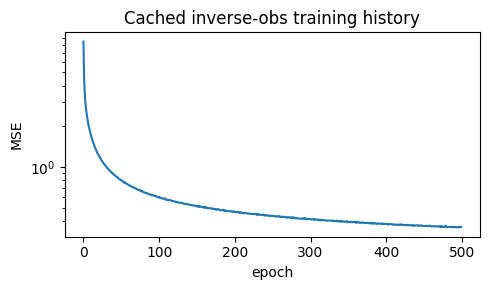

In [7]:
INVERTER_CKPT = 'l96_inverter_sigma0.0_n32000_ep500.pt'

inverter = InverseObsLorenz96(obs_grid=10, full_grid=40, hidden=32, n_layers=6).to(device)
ckpt = load_cache(INVERTER_CKPT)
if ckpt is None:
    raise FileNotFoundError(
        f'Missing cached CNN weights: {cache_path(INVERTER_CKPT)}\n'
        'Run the parent notebook training cell once, or set INVOBS_CACHE_DIR to a cache '
        'directory that already contains this checkpoint.'
    )

inverter.load_state_dict(ckpt['state_dict'])
inverter.eval()
hist = ckpt.get('hist')
print(f'Loaded cached inverse-observation CNN: {INVERTER_CKPT}')

if hist is not None:
    plt.figure(figsize=(5, 3))
    plt.plot(hist)
    plt.yscale('log')
    plt.xlabel('epoch')
    plt.ylabel('MSE')
    plt.title('Cached inverse-obs training history')
    plt.tight_layout()
    plt.show()

---
## What This Version Fixes

The earlier window sweep was useful as a stress test, but it mixed several effects:

- Different windows used different random seeds, so `T=5` and `T=50` were not evaluated on the same trajectories.
- The optimizer solved one batched L-BFGS problem, so the line search and quasi-Newton history were shared across samples.
- Gradient norms came from a loss averaged over the whole batch, which can hide a single bad trajectory.
- The inverse CNN was trained with `T_train=20`, but the sweep evaluates other window lengths; this is allowed by the convolutional network, but it is a distribution shift.

This notebook addresses those points by using one shared max-length evaluation dataset, slicing each assimilation window from it, optionally running independent per-sample DA, and adding inverse-model reconstruction diagnostics so the `T_train=20` mismatch is visible.

---
## Full 4D-Var Equation, Not Implemented Here

The strong-constraint 4D-Var objective is usually written as

$$
J(x_0) = \frac{1}{2}(x_0 - x_b)^T B^{-1}(x_0 - x_b)
       + \frac{1}{2}\sum_{t=0}^{T-1}(y_t - H(M_t(x_0)))^T R^{-1}(y_t - H(M_t(x_0))).
$$

The pieces mean:

- `$x_0$`: the unknown initial state being optimized. Better `$x_0$` means better forecasts after the assimilation window.
- `$M_t(x_0)$`: the dynamical model integrated from `$x_0$` to time `$t`. For Lorenz96 this is the RK4 integrator.
- `$H$`: the observation operator. Here it keeps every fourth grid point, so many state variables are hidden.
- `$y_t$`: the observed data at time `$t`.
- `$x_b$`: the background or prior guess. This can be a baseline interpolation, an inverse-CNN estimate, or another forecast.
- `$B$`: background-error covariance. Large variance in `$B$` means the optimizer is allowed to move far from `$x_b$`; small variance forces the solution to stay close to the background. Correlations in `$B$` also impose spatial structure.
- `$R$`: observation-error covariance. Small `$R$` means observations are trusted strongly; large `$R$` means noisy observations are downweighted.

This notebook does not implement the `$B$` or `$R$` terms. It uses the simpler paper-style losses:

$$J_{obs}(x_0) = \frac{1}{T}\sum_t \|H(M_t(x_0)) - y_t\|^2,$$

and

$$J_{phys}(x_0) = \frac{1}{T}\sum_t \|M_t(x_0) - H^{-1}_\theta(y)_{t}\|^2.$$

Observation optimization directly matches observations. Physics optimization first lifts observations into full state space with the learned inverse operator. Hybrid optimization runs physics-space L-BFGS first, then observation-space L-BFGS. In prediction terms, `$B$` would control how much the initial condition trusts the prior, `$R$` would control how much it trusts noisy observations, and the window length controls how much temporal information is used before the forecast begins. Longer windows can improve identifiability, but chaotic dynamics also make gradients harder.

In [8]:
import time

USE_DATA_CACHE = True
USE_DA_CACHE = True
SAVE_DA_CACHE = True
FORCE_RECOMPUTE_DA = False

RUN_PROFILE = 'balanced'  # 'quick' for iteration, 'balanced' for smoother plots, 'final' for the slow faithful sweep.
RUN_PROFILES = {
    'quick': dict(
        assim_windows=[1, 5, 8, 10, 13, 20],
        n_eval=8,
        optimize_per_sample=False,
        obs_steps=80,
        hybrid_physics_steps=20,
        hybrid_obs_steps=60,
        max_eval_per_stage=100,
        compare_t_trains=[10, 20, 30],
        compare_t_evals=[10, 20, 30],
    ),
    'balanced': dict(
        assim_windows=[1, 5, 8, 9, 10, 11, 12, 13, 20, 40],
        n_eval=16,
        optimize_per_sample=False,
        obs_steps=200,
        hybrid_physics_steps=50,
        hybrid_obs_steps=150,
        max_eval_per_stage=250,
        compare_t_trains=[10, 20, 30],
        compare_t_evals=[10, 20, 30],
    ),
    'final': dict(
        assim_windows=[1, 5, 8, 9, 10, 11, 12, 13, 20, 40],
        n_eval=32,
        optimize_per_sample=True,
        obs_steps=500,
        hybrid_physics_steps=100,
        hybrid_obs_steps=400,
        max_eval_per_stage=None,
        compare_t_trains=[10, 20, 30],
        compare_t_evals=[10, 20, 30],
    ),
}
if RUN_PROFILE not in RUN_PROFILES:
    raise ValueError(f'Unknown RUN_PROFILE={RUN_PROFILE!r}. Use one of {sorted(RUN_PROFILES)}')
_run_cfg = RUN_PROFILES[RUN_PROFILE]

ASSIM_WINDOWS = _run_cfg['assim_windows']
N_EVAL = _run_cfg['n_eval']
T_FORECAST = 40
OBS_NOISE_STD = 0.0
N_WARMUP = 500
BASE_SEED = 1706

OPTIMIZE_PER_SAMPLE = _run_cfg['optimize_per_sample']
OBS_STEPS = _run_cfg['obs_steps']
HYBRID_PHYSICS_STEPS = _run_cfg['hybrid_physics_steps']
HYBRID_OBS_STEPS = _run_cfg['hybrid_obs_steps']
MAX_EVAL_PER_STAGE = _run_cfg['max_eval_per_stage']
GRAD_EXPLODE_THRESHOLD = 1e8

METHODS = {
    'baseline init + observation opt': dict(init='baseline', p_steps=0, o_steps=OBS_STEPS),
    'inverse init + observation opt':  dict(init='invobs',   p_steps=0, o_steps=OBS_STEPS),
    'baseline init + hybrid opt':      dict(init='baseline', p_steps=HYBRID_PHYSICS_STEPS, o_steps=HYBRID_OBS_STEPS),
    'inverse init + hybrid opt':       dict(init='invobs',   p_steps=HYBRID_PHYSICS_STEPS, o_steps=HYBRID_OBS_STEPS),
}

colors = {
    'baseline init + observation opt': '#999999',
    'inverse init + observation opt':  '#0072B2',
    'baseline init + hybrid opt':      '#D55E00',
    'inverse init + hybrid opt':       '#009E73',
}
linestyles = {
    'baseline init + observation opt': '-',
    'inverse init + observation opt': '--',
    'baseline init + hybrid opt': '-.',
    'inverse init + hybrid opt': ':',
}

DATA_CACHE_VERSION = 1
DA_CACHE_VERSION = 2
T_TOTAL_MAX = max(ASSIM_WINDOWS) + T_FORECAST


def clean_tag(text):
    return ''.join(ch if ch.isalnum() else '_' for ch in text).strip('_')


def shared_data_cache_key():
    return (
        f'l96_corrected_shared_eval_v{DATA_CACHE_VERSION}_'
        f'N{N_EVAL}_Ttotal{T_TOTAL_MAX}_sigma{OBS_NOISE_STD}_'
        f'warmup{N_WARMUP}_seed{BASE_SEED}.pt'
    )


def da_cache_key(T_assim, method):
    mode = 'independent' if OPTIMIZE_PER_SAMPLE else 'batched'
    cfg = METHODS[method]
    return (
        f'l96_corrected_da_v{DA_CACHE_VERSION}_{mode}_'
        f'ckpt{os.path.splitext(INVERTER_CKPT)[0]}_'
        f'T{T_assim}_method{clean_tag(method)}_N{N_EVAL}_forecast{T_FORECAST}_'
        f'sigma{OBS_NOISE_STD}_seed{BASE_SEED}_'
        f'p{cfg["p_steps"]}_o{cfg["o_steps"]}.pt'
    )

print('run profile:', RUN_PROFILE)
print('windows:', ASSIM_WINDOWS)
print('shared trajectories:', N_EVAL)
print('max truth length:', T_TOTAL_MAX)
print('per-sample optimization:', OPTIMIZE_PER_SAMPLE)
print('DA optimizer jobs:', len(ASSIM_WINDOWS) * len(METHODS) * (N_EVAL if OPTIMIZE_PER_SAMPLE else 1))
print('LBFGS steps: obs=', OBS_STEPS, 'hybrid=', (HYBRID_PHYSICS_STEPS, HYBRID_OBS_STEPS), 'max eval/stage=', MAX_EVAL_PER_STAGE)
print('shared data cache:', shared_data_cache_key())
print('example DA cache:', da_cache_key(ASSIM_WINDOWS[0], next(iter(METHODS))))
COMPARE_T_TRAINS = _run_cfg['compare_t_trains']
COMPARE_T_EVALS = _run_cfg['compare_t_evals']
COMPARE_ALL_WINDOWS = sorted(set(ASSIM_WINDOWS) | set(COMPARE_T_EVALS))
COMPARE_REUSE_MAIN_T20 = True
COMPARE_AUTO_TRAIN = True
COMPARE_PROFILE = 'fast'  # Set to 'full' to rerun the heavier comparison training job.
COMPARE_PROFILES = {
    'fast': dict(n_train=4000, n_epochs=60, batch_size=256, warmup=500, log_every=10),
    'full': dict(n_train=32000, n_epochs=500, batch_size=256, warmup=1000, log_every=50),
}
if COMPARE_PROFILE not in COMPARE_PROFILES:
    raise ValueError(f'Unknown COMPARE_PROFILE={COMPARE_PROFILE!r}. Use one of {sorted(COMPARE_PROFILES)}')
_compare_cfg = COMPARE_PROFILES[COMPARE_PROFILE]
COMPARE_N_TRAIN = _compare_cfg['n_train']
COMPARE_N_EPOCHS = _compare_cfg['n_epochs']
COMPARE_BATCH_SIZE = _compare_cfg['batch_size']
COMPARE_WARMUP = _compare_cfg['warmup']
COMPARE_LOG_EVERY = _compare_cfg['log_every']
COMPARE_LR = 1e-3
COMPARE_SEED = 42
INVOBS_COMPARE_VERSION = 2


def compare_model_label(T_train):
    if T_train == 20 and COMPARE_REUSE_MAIN_T20:
        return 'T_train=20 (main ckpt)'
    return f'T_train={T_train}'


def compare_model_ckpt_key(T_train):
    if T_train == 20 and COMPARE_REUSE_MAIN_T20:
        return INVERTER_CKPT
    return (
        f'l96_inverter_compare_v{INVOBS_COMPARE_VERSION}_'
        f'profile{COMPARE_PROFILE}_Ttrain{T_train}_n{COMPARE_N_TRAIN}_'
        f'ep{COMPARE_N_EPOCHS}_b{COMPARE_BATCH_SIZE}_'
        f'warmup{COMPARE_WARMUP}_lr{COMPARE_LR:g}_sigma{OBS_NOISE_STD}.pt'
    )


def compare_results_cache_key():
    train_tag = '-'.join(str(t) for t in COMPARE_T_TRAINS)
    eval_tag = '-'.join(str(t) for t in COMPARE_T_EVALS)
    return (
        f'l96_invobs_cross_eval_v{INVOBS_COMPARE_VERSION}_'
        f'profile{COMPARE_PROFILE}_train{train_tag}_eval{eval_tag}_n{N_EVAL}_'
        f'trainN{COMPARE_N_TRAIN}_ep{COMPARE_N_EPOCHS}_'
        f'b{COMPARE_BATCH_SIZE}_warmup{COMPARE_WARMUP}_sigma{OBS_NOISE_STD}.pt'
    )


def compare_steps_per_epoch():
    return (COMPARE_N_TRAIN + COMPARE_BATCH_SIZE - 1) // COMPARE_BATCH_SIZE


def compare_total_updates():
    return compare_steps_per_epoch() * COMPARE_N_EPOCHS


print('compare profile:', COMPARE_PROFILE, COMPARE_PROFILES[COMPARE_PROFILE])
print('compare T_train values:', COMPARE_T_TRAINS)
print('compare anchor eval windows:', COMPARE_T_EVALS)
print('compare optimizer updates/model:', compare_total_updates())
print('compare results cache:', compare_results_cache_key())

run profile: balanced
windows: [1, 5, 8, 9, 10, 11, 12, 13, 20, 40]
shared trajectories: 16
max truth length: 80
per-sample optimization: False
DA optimizer jobs: 40
LBFGS steps: obs= 200 hybrid= (50, 150) max eval/stage= 250
shared data cache: l96_corrected_shared_eval_v1_N16_Ttotal80_sigma0.0_warmup500_seed1706.pt
example DA cache: l96_corrected_da_v2_batched_ckptl96_inverter_sigma0.0_n32000_ep500_T1_methodbaseline_init___observation_opt_N16_forecast40_sigma0.0_seed1706_p0_o200.pt
compare profile: fast {'n_train': 4000, 'n_epochs': 60, 'batch_size': 256, 'warmup': 500, 'log_every': 10}
compare T_train values: [10, 20, 30]
compare anchor eval windows: [10, 20, 30]
compare optimizer updates/model: 960
compare results cache: l96_invobs_cross_eval_v2_profilefast_train10-20-30_eval10-20-30_n16_trainN4000_ep60_b256_warmup500_sigma0.0.pt


### Shared Evaluation Dataset

The maximum-length truth and observations are generated once with one seed. Each assimilation window then uses `Y_eval[:, :T]` and compares against `X_eval[:, :T + T_FORECAST]`. This makes the window-size comparison about window length rather than a different random batch of initial conditions.

In [9]:
data_key = shared_data_cache_key()
shared = load_cache(data_key) if USE_DATA_CACHE else None

if shared is None:
    X0_eval, X_eval, Y_eval, Y_clean_eval = generate_data(
        L96, n_samples=N_EVAL, n_time_steps=T_TOTAL_MAX,
        n_warmup=N_WARMUP, obs_noise_std=OBS_NOISE_STD, seed=BASE_SEED,
    )
    shared = {
        'X0': X0_eval.detach().cpu(),
        'X': X_eval.detach().cpu(),
        'Y': Y_eval.detach().cpu(),
        'Y_clean': Y_clean_eval.detach().cpu(),
        'metadata': dict(N_EVAL=N_EVAL, T_TOTAL_MAX=T_TOTAL_MAX, seed=BASE_SEED),
    }
    save_cache(shared, data_key)
else:
    print(f'Loaded shared evaluation data: {data_key}')

X0_eval = shared['X0'].to(device)
X_eval = shared['X'].to(device)
Y_eval = shared['Y'].to(device)
Y_clean_eval = shared['Y_clean'].to(device)

print('X0_eval:', tuple(X0_eval.shape))
print('X_eval:', tuple(X_eval.shape))
print('Y_eval:', tuple(Y_eval.shape))

  [cache] loaded l96_corrected_shared_eval_v1_N16_Ttotal80_sigma0.0_warmup500_seed1706.pt
Loaded shared evaluation data: l96_corrected_shared_eval_v1_N16_Ttotal80_sigma0.0_warmup500_seed1706.pt
X0_eval: (16, 40)
X_eval: (16, 80, 40)
Y_eval: (16, 80, 10)


### Cross-Window Inverse-CNN Generalization Test

This test tries to answer a narrower question than the DA sweep: is the reconstruction gap mostly because the inverse model was trained at `T_train=20`, or because the observation inversion problem itself changes with window length?

The setup is:

- train/cache inverse models for `T_train=10` and `T_train=30` if they are missing;
- reuse the main cached `T_train=20` CNN;
- evaluate all of them on the same held-out trajectories at `T_eval = 10, 20, 30`;
- also plot reconstruction error across the full sweep windows plus those anchor eval windows.

This section is intentionally reconstruction-only. It isolates the inverse observation operator from the DA optimizer.

By default it now uses a lighter `COMPARE_PROFILE='fast'` setting so the first diagnostic run is much cheaper. Switch `COMPARE_PROFILE='full'` in the config cell if you want the original heavier training job.

In [10]:
def train_inverter_cached(
    dyn_sys, inverter_model, *, n_train, T_train, n_warmup, n_epochs, batch_size, lr,
    obs_noise_std=0.0, log_every=50, seed=42,
):
    data_key = (
        f'l96_train_data_n{n_train}_T{T_train}'
        f'_warmup{n_warmup}_sigma{obs_noise_std}.pt'
    )
    data = load_cache(data_key)
    if data is None:
        print(f'  generating {n_train} training trajectories for T_train={T_train}...')
        _, X, Y, _ = generate_data(
            dyn_sys, n_train, T_train, n_warmup,
            obs_noise_std=obs_noise_std, seed=seed,
        )
        X = X.detach()
        Y = Y.detach()
        save_cache({'X': X, 'Y': Y}, data_key)
    else:
        X, Y = data['X'], data['Y']

    opt = torch.optim.Adam(inverter_model.parameters(), lr=lr)
    n = X.shape[0]
    history = []
    for epoch in range(n_epochs):
        perm = torch.randperm(n, device=device)
        ep_loss = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            y_b, x_b = Y[idx], X[idx]
            pred = inverter_model(y_b)
            loss = F.mse_loss(pred, x_b)
            opt.zero_grad()
            loss.backward()
            opt.step()
            ep_loss += loss.item() * idx.numel()
        ep_loss /= n
        history.append(ep_loss)
        if epoch % log_every == 0 or epoch == n_epochs - 1:
            print(f'  T_train={T_train:3d}  epoch {epoch:3d}  loss={ep_loss:.4f}')
    return history


def load_or_train_compare_inverter(T_train):
    label = compare_model_label(T_train)
    if T_train == 20 and COMPARE_REUSE_MAIN_T20:
        print(f'Using existing main checkpoint for {label}')
        return inverter, {'label': label, 'ckpt_key': INVERTER_CKPT, 'reused_main': True}

    ckpt_key = compare_model_ckpt_key(T_train)
    model = InverseObsLorenz96(obs_grid=10, full_grid=40, hidden=32, n_layers=6).to(device)
    ckpt = load_cache(ckpt_key)
    if ckpt is None:
        if not COMPARE_AUTO_TRAIN:
            raise FileNotFoundError(
                f'Missing comparison checkpoint {cache_path(ckpt_key)} and COMPARE_AUTO_TRAIN=False'
            )
        print(
            f'Training comparison inverse model for T_train={T_train} '
            f'with profile={COMPARE_PROFILE} '
            f'(n_train={COMPARE_N_TRAIN}, epochs={COMPARE_N_EPOCHS}, '
            f'batch={COMPARE_BATCH_SIZE}, warmup={COMPARE_WARMUP})...'
        )
        hist = train_inverter_cached(
            L96, model,
            n_train=COMPARE_N_TRAIN,
            T_train=T_train,
            n_warmup=COMPARE_WARMUP,
            n_epochs=COMPARE_N_EPOCHS,
            batch_size=COMPARE_BATCH_SIZE,
            lr=COMPARE_LR,
            obs_noise_std=OBS_NOISE_STD,
            log_every=COMPARE_LOG_EVERY,
            seed=COMPARE_SEED,
        )
        save_cache(
            {
                'state_dict': model.state_dict(),
                'hist': hist,
                'metadata': {
                    'T_train': T_train,
                    'n_train': COMPARE_N_TRAIN,
                    'n_epochs': COMPARE_N_EPOCHS,
                },
            },
            ckpt_key,
        )
    else:
        model.load_state_dict(ckpt['state_dict'])
        hist = ckpt.get('hist')
        if hist is not None:
            print(f'Loaded cached comparison model for T_train={T_train}: {ckpt_key}')
    model.eval()
    return model, {'label': label, 'ckpt_key': ckpt_key, 'reused_main': False}


compare_inverters = {}
compare_model_meta = {}
for T_train in COMPARE_T_TRAINS:
    model, meta = load_or_train_compare_inverter(T_train)
    compare_inverters[T_train] = model
    compare_model_meta[T_train] = meta

print('comparison models ready:', [compare_model_meta[t]['label'] for t in COMPARE_T_TRAINS])

  [cache] loaded l96_inverter_compare_v2_profilefast_Ttrain10_n4000_ep60_b256_warmup500_lr0.001_sigma0.0.pt
Loaded cached comparison model for T_train=10: l96_inverter_compare_v2_profilefast_Ttrain10_n4000_ep60_b256_warmup500_lr0.001_sigma0.0.pt
Using existing main checkpoint for T_train=20 (main ckpt)
  [cache] loaded l96_inverter_compare_v2_profilefast_Ttrain30_n4000_ep60_b256_warmup500_lr0.001_sigma0.0.pt
Loaded cached comparison model for T_train=30: l96_inverter_compare_v2_profilefast_Ttrain30_n4000_ep60_b256_warmup500_lr0.001_sigma0.0.pt
comparison models ready: ['T_train=10', 'T_train=20 (main ckpt)', 'T_train=30']


  [cache] loaded l96_invobs_cross_eval_v2_profilefast_train10-20-30_eval10-20-30_n16_trainN4000_ep60_b256_warmup500_sigma0.0.pt
Loaded cached cross-window inverse-model results: l96_invobs_cross_eval_v2_profilefast_train10-20-30_eval10-20-30_n16_trainN4000_ep60_b256_warmup500_sigma0.0.pt


,label,T_eval,seq_l1_mean,seq_l1_p90,x0_rmse_mean,x0_rmse_p90
0,T_train=10,10,1.038574,1.248081,1.670277,2.132221
1,T_train=10,20,0.953115,1.169017,1.670277,2.132221
2,T_train=10,30,0.937009,1.184198,1.670277,2.132221
3,T_train=20 (main ckpt),10,0.420311,0.552889,0.926715,1.332921
4,T_train=20 (main ckpt),20,0.372743,0.492487,0.926715,1.332921
5,T_train=20 (main ckpt),30,0.351126,0.460359,0.926715,1.332921
6,T_train=30,10,1.036995,1.278561,1.814294,2.108146
7,T_train=30,20,0.918243,1.155465,1.814294,2.108146
8,T_train=30,30,0.880754,1.117301,1.814294,2.108146


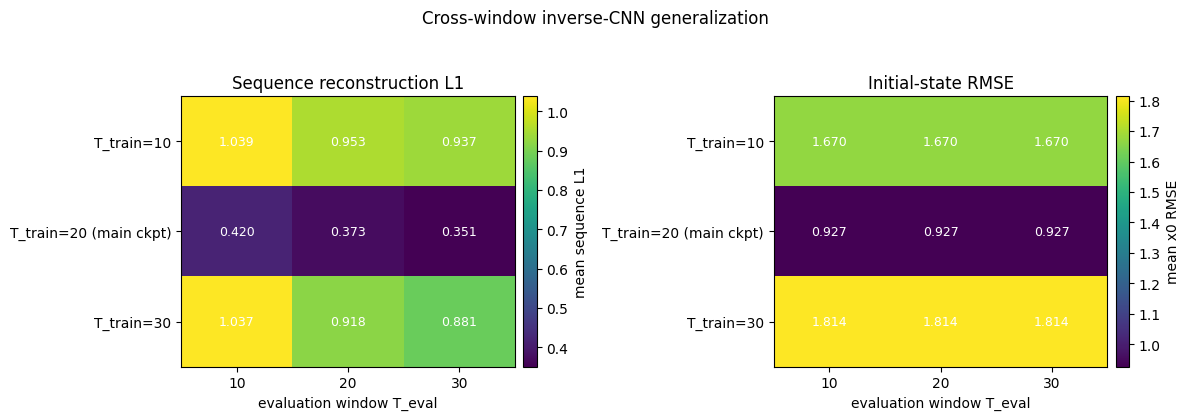

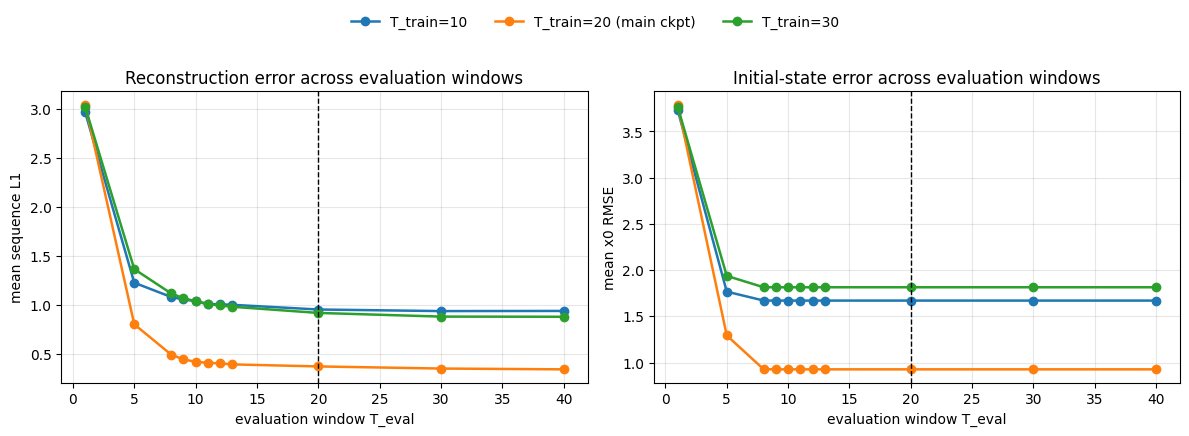

In [11]:
def evaluate_inverse_model(model, T_eval):
    Y_T = Y_eval[:, :T_eval]
    X_T = X_eval[:, :T_eval]
    with torch.no_grad():
        X_hat = model(Y_T)
    seq_l1_samples = (X_hat - X_T).abs().mean(dim=(1, 2)).detach().cpu().numpy()
    x0_rmse_samples = ((X_hat[:, 0] - X0_eval) ** 2).mean(dim=-1).sqrt().detach().cpu().numpy()
    return {
        'seq_l1_mean': float(seq_l1_samples.mean()),
        'seq_l1_p90': float(np.percentile(seq_l1_samples, 90)),
        'x0_rmse_mean': float(x0_rmse_samples.mean()),
        'x0_rmse_p90': float(np.percentile(x0_rmse_samples, 90)),
        'seq_l1_samples': seq_l1_samples,
        'x0_rmse_samples': x0_rmse_samples,
    }


cross_eval_cache_key = compare_results_cache_key()
cross_eval_cache = load_cache(cross_eval_cache_key)

if cross_eval_cache is None:
    invobs_cross_rows = []
    invobs_curve_rows = []
    for T_train in COMPARE_T_TRAINS:
        model = compare_inverters[T_train]
        label = compare_model_meta[T_train]['label']
        for T_eval in COMPARE_T_EVALS:
            metrics = evaluate_inverse_model(model, T_eval)
            invobs_cross_rows.append({
                'T_train': T_train,
                'label': label,
                'T_eval': T_eval,
                **metrics,
            })
        for T_eval in COMPARE_ALL_WINDOWS:
            metrics = evaluate_inverse_model(model, T_eval)
            invobs_curve_rows.append({
                'T_train': T_train,
                'label': label,
                'T_eval': T_eval,
                'seq_l1_mean': metrics['seq_l1_mean'],
                'x0_rmse_mean': metrics['x0_rmse_mean'],
            })
    save_cache(
        {
            'cross_rows': invobs_cross_rows,
            'curve_rows': invobs_curve_rows,
        },
        cross_eval_cache_key,
    )
else:
    invobs_cross_rows = cross_eval_cache['cross_rows']
    invobs_curve_rows = cross_eval_cache['curve_rows']
    print(f'Loaded cached cross-window inverse-model results: {cross_eval_cache_key}')

try:
    import pandas as pd
    df_invobs_cross = pd.DataFrame(invobs_cross_rows)
    df_invobs_curve = pd.DataFrame(invobs_curve_rows)
    display(df_invobs_cross[['label', 'T_eval', 'seq_l1_mean', 'seq_l1_p90', 'x0_rmse_mean', 'x0_rmse_p90']])
except Exception:
    df_invobs_cross = None
    df_invobs_curve = None
    for row in invobs_cross_rows:
        print(row)

if df_invobs_cross is not None:
    seq_pivot = df_invobs_cross.pivot(index='label', columns='T_eval', values='seq_l1_mean')
    x0_pivot = df_invobs_cross.pivot(index='label', columns='T_eval', values='x0_rmse_mean')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, pivot, title, cbar_label in [
        (axes[0], seq_pivot, 'Sequence reconstruction L1', 'mean sequence L1'),
        (axes[1], x0_pivot, 'Initial-state RMSE', 'mean x0 RMSE'),
    ]:
        values = pivot.values.astype(float)
        im = ax.imshow(values, aspect='auto', cmap='viridis')
        ax.set_xticks(np.arange(len(pivot.columns)))
        ax.set_xticklabels(pivot.columns)
        ax.set_yticks(np.arange(len(pivot.index)))
        ax.set_yticklabels(pivot.index)
        ax.set_xlabel('evaluation window T_eval')
        ax.set_title(title)
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                ax.text(j, i, f'{values[i, j]:.3f}', ha='center', va='center', color='white', fontsize=9)
        fig.colorbar(im, ax=ax, pad=0.02, label=cbar_label)
    fig.suptitle('Cross-window inverse-CNN generalization', y=0.99)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    for T_train in COMPARE_T_TRAINS:
        label = compare_model_meta[T_train]['label']
        rows = df_invobs_curve[df_invobs_curve['T_train'] == T_train].sort_values('T_eval')
        xs = rows['T_eval'].to_numpy()
        axes[0].plot(xs, rows['seq_l1_mean'].to_numpy(), marker='o', lw=1.8, label=label)
        axes[1].plot(xs, rows['x0_rmse_mean'].to_numpy(), marker='o', lw=1.8, label=label)
    for ax, ylabel, title in [
        (axes[0], 'mean sequence L1', 'Reconstruction error across evaluation windows'),
        (axes[1], 'mean x0 RMSE', 'Initial-state error across evaluation windows'),
    ]:
        ax.axvline(20, color='k', ls='--', lw=1.0)
        ax.set_xlabel('evaluation window T_eval')
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(alpha=0.3)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False)
    plt.tight_layout(rect=(0, 0, 1, 0.90))
    plt.show()

### Simple DA Loss and Optimizer

`OPTIMIZE_PER_SAMPLE=True` runs L-BFGS separately for every trajectory. This is slower than the old batched objective, but the gradient diagnostics are no longer diluted by a batch mean and each sample has its own line search.

In [12]:
def decorrelate(x, C_inv_sqrt):
    return x @ C_inv_sqrt


def correlate(z, C_sqrt):
    return z @ C_sqrt


def baseline_init_l96(dyn_sys, Y):
    if Y.ndim == 3:
        return Y[:, 0].repeat_interleave(dyn_sys.observe_every, dim=-1)
    return Y[0].repeat_interleave(dyn_sys.observe_every)


def invobs_init_l96(inverter, Y):
    with torch.no_grad():
        return inverter(Y).detach()[:, 0]


def make_da_loss(Y, dyn_sys, C_sqrt, T, mode, inverter=None):
    if mode == 'physics':
        assert inverter is not None
        with torch.no_grad():
            target = inverter(Y).detach().transpose(0, 1)
    elif mode == 'obs':
        target = Y.transpose(0, 1)
    else:
        raise ValueError(mode)

    def loss_fn(Z0):
        X0 = correlate(Z0, C_sqrt)
        traj = dyn_sys.integrate(X0, T)
        if mode == 'obs':
            pred = dyn_sys.observe(traj)
        else:
            pred = traj
        return ((pred - target) ** 2).mean()

    return loss_fn


def lbfgs_minimize(loss_fn, z0_init, max_iter=200, max_eval=None, history_size=20, lr=1.0):
    z = z0_init.clone().detach().requires_grad_(True)
    kwargs = dict(
        max_iter=max_iter,
        history_size=history_size,
        tolerance_grad=1e-12,
        tolerance_change=1e-12,
        line_search_fn='strong_wolfe',
        lr=lr,
    )
    if max_eval is not None:
        kwargs['max_eval'] = max_eval
    opt = torch.optim.LBFGS([z], **kwargs)
    diag = {
        'loss': [],
        'grad_norm': [],
        'grad_abs_max': [],
        'status': 'ok',
        'exception': None,
        'optimizer_n_iter': None,
        'optimizer_func_evals': None,
    }

    def closure():
        opt.zero_grad()
        loss = loss_fn(z)
        if not torch.isfinite(loss):
            raise FloatingPointError(f'nonfinite loss: {loss.item()}')
        loss.backward()
        grad = z.grad.detach()
        grad_norm = torch.linalg.vector_norm(grad).item()
        grad_abs_max = grad.abs().max().item()
        diag['loss'].append(loss.item())
        diag['grad_norm'].append(grad_norm)
        diag['grad_abs_max'].append(grad_abs_max)
        if not np.isfinite(grad_norm) or not np.isfinite(grad_abs_max):
            raise FloatingPointError(f'nonfinite gradient: norm={grad_norm}, max={grad_abs_max}')
        return loss

    try:
        opt.step(closure)
    except Exception as exc:
        diag['status'] = 'failed'
        diag['exception'] = repr(exc)
    state = opt.state.get(z, {})
    diag['optimizer_n_iter'] = int(state.get('n_iter', -1)) if state else None
    diag['optimizer_func_evals'] = int(state.get('func_evals', -1)) if state else None
    return z.detach(), diag


def run_da_single(dyn_sys, inverter, corr, x0_init, y_T, T, physics_steps=0, obs_steps=500):
    C_sqrt, C_inv_sqrt = corr['C_sqrt'], corr['C_inv_sqrt']
    X0_init = x0_init.unsqueeze(0) if x0_init.ndim == 1 else x0_init
    Y = y_T.unsqueeze(0) if y_T.ndim == 2 else y_T
    Z0 = decorrelate(X0_init, C_inv_sqrt)
    stage_diags = []

    if physics_steps > 0:
        loss_p = make_da_loss(Y, dyn_sys, C_sqrt, T, mode='physics', inverter=inverter)
        Z0, diag_p = lbfgs_minimize(loss_p, Z0, max_iter=physics_steps, max_eval=MAX_EVAL_PER_STAGE)
        diag_p['stage'] = 'physics'
        stage_diags.append(diag_p)
        if diag_p['status'] != 'ok':
            return correlate(Z0, C_sqrt).squeeze(0), stage_diags

    if obs_steps > 0:
        loss_o = make_da_loss(Y, dyn_sys, C_sqrt, T, mode='obs')
        Z0, diag_o = lbfgs_minimize(loss_o, Z0, max_iter=obs_steps, max_eval=MAX_EVAL_PER_STAGE)
        diag_o['stage'] = 'obs'
        stage_diags.append(diag_o)

    return correlate(Z0, C_sqrt).squeeze(0), stage_diags


def run_da_batched(dyn_sys, inverter, corr, X0_init, Y, T, physics_steps=0, obs_steps=500):
    C_sqrt, C_inv_sqrt = corr['C_sqrt'], corr['C_inv_sqrt']
    Z0 = decorrelate(X0_init, C_inv_sqrt)
    stage_diags = []

    if physics_steps > 0:
        loss_p = make_da_loss(Y, dyn_sys, C_sqrt, T, mode='physics', inverter=inverter)
        Z0, diag_p = lbfgs_minimize(loss_p, Z0, max_iter=physics_steps, max_eval=MAX_EVAL_PER_STAGE)
        diag_p['stage'] = 'physics'
        stage_diags.append(diag_p)
        if diag_p['status'] != 'ok':
            return correlate(Z0, C_sqrt), [stage_diags for _ in range(Y.shape[0])]

    if obs_steps > 0:
        loss_o = make_da_loss(Y, dyn_sys, C_sqrt, T, mode='obs')
        Z0, diag_o = lbfgs_minimize(loss_o, Z0, max_iter=obs_steps, max_eval=MAX_EVAL_PER_STAGE)
        diag_o['stage'] = 'obs'
        stage_diags.append(diag_o)

    return correlate(Z0, C_sqrt), [stage_diags for _ in range(Y.shape[0])]

In [13]:
def stage_values(sample_stage_diags, key, stage=None):
    vals = []
    for sample_diags in sample_stage_diags:
        for diag in sample_diags:
            if stage is None or diag.get('stage') == stage:
                vals.extend(diag.get(key, []))
    return vals


def sample_stage_summary(sample_stage_diags):
    closure_counts = []
    max_grad_norms = []
    max_grad_abs = []
    failed = []
    for sample_diags in sample_stage_diags:
        n_closure = 0
        sample_grad = []
        sample_abs = []
        sample_failed = False
        for diag in sample_diags:
            n_closure += len(diag.get('grad_norm', []))
            sample_grad.extend(diag.get('grad_norm', []))
            sample_abs.extend(diag.get('grad_abs_max', []))
            sample_failed = sample_failed or diag.get('status') != 'ok'
        closure_counts.append(n_closure)
        max_grad_norms.append(max(sample_grad) if sample_grad else np.nan)
        max_grad_abs.append(max(sample_abs) if sample_abs else np.nan)
        failed.append(sample_failed)
    return np.asarray(closure_counts), np.asarray(max_grad_norms), np.asarray(max_grad_abs), np.asarray(failed)


def summarize_result(method, T_assim, X0_opt, X0_truth, X_truth_total, sample_stage_diags, elapsed_s):
    T_total = T_assim + T_FORECAST
    X_pred = L96.integrate(X0_opt.to(device), T_total).permute(1, 0, 2)
    err = (X_pred - X_truth_total.to(device)).abs().detach().cpu().numpy()
    l1_t_samples = err.mean(axis=-1)
    l1_t = l1_t_samples.mean(axis=0)
    x0_rmse_samples = ((X0_opt.cpu() - X0_truth.cpu()) ** 2).mean(dim=-1).sqrt().numpy()
    forecast_l1_samples = l1_t_samples[:, T_assim:].mean(axis=1)
    assim_l1_samples = l1_t_samples[:, :T_assim].mean(axis=1)
    end_assim_l1_samples = l1_t_samples[:, max(T_assim - 1, 0)]
    final_l1_samples = l1_t_samples[:, -1]
    closure_counts, max_grad_norms, max_grad_abs, failed = sample_stage_summary(sample_stage_diags)

    max_grad_norm = float(np.nanmax(max_grad_norms)) if len(max_grad_norms) else float('nan')
    max_grad_abs_val = float(np.nanmax(max_grad_abs)) if len(max_grad_abs) else float('nan')
    failed_count = int(failed.sum())
    exploded = (
        failed_count > 0
        or not np.isfinite(max_grad_norm)
        or not np.isfinite(max_grad_abs_val)
        or max_grad_norm > GRAD_EXPLODE_THRESHOLD
        or max_grad_abs_val > GRAD_EXPLODE_THRESHOLD
    )

    return {
        'window': T_assim,
        'method': method,
        'status': 'ok' if failed_count == 0 else 'failed',
        'exploded': exploded,
        'failed_count': failed_count,
        'x0_rmse_mean': float(x0_rmse_samples.mean()),
        'x0_rmse_median': float(np.median(x0_rmse_samples)),
        'assim_l1_mean': float(assim_l1_samples.mean()),
        'end_assim_l1_mean': float(end_assim_l1_samples.mean()),
        'forecast_l1_mean': float(forecast_l1_samples.mean()),
        'forecast_l1_median': float(np.median(forecast_l1_samples)),
        'forecast_l1_p90': float(np.percentile(forecast_l1_samples, 90)),
        'final_l1_mean': float(final_l1_samples.mean()),
        'max_grad_norm': max_grad_norm,
        'max_grad_abs': max_grad_abs_val,
        'grad_norm_p90_sample': float(np.nanpercentile(max_grad_norms, 90)),
        'closures_mean': float(np.nanmean(closure_counts)),
        'closures_max': int(np.nanmax(closure_counts)),
        'elapsed_s': float(elapsed_s),
        'l1_t': l1_t,
        'l1_t_samples': l1_t_samples,
        'x0_rmse_samples': x0_rmse_samples,
        'forecast_l1_samples': forecast_l1_samples,
        'assim_l1_samples': assim_l1_samples,
        'end_assim_l1_samples': end_assim_l1_samples,
        'final_l1_samples': final_l1_samples,
        'closure_counts': closure_counts,
        'max_grad_norm_samples': max_grad_norms,
        'max_grad_abs_samples': max_grad_abs,
        'sample_stage_diags': sample_stage_diags,
        'x0_opt': X0_opt.detach().cpu(),
    }


def print_result(row):
    flag = 'EXPLODED' if row['exploded'] else 'ok'
    print(
        f"T={row['window']:3d} | {row['method']:<32s} | {flag:<8s} "
        f"forecast={row['forecast_l1_mean']:.4f} end_assim={row['end_assim_l1_mean']:.4f} "
        f"max_grad={row['max_grad_norm']:.3e} closures_mean={row['closures_mean']:.1f} "
        f"failures={row['failed_count']} time={row['elapsed_s']:.1f}s"
    )

### Reference Fixed-CNN Diagnostic

This is the original single-model diagnostic for the main `T_train=20` DA checkpoint. It is still useful as a quick reference, but the cross-window section above is the more direct answer to the training-window mismatch question.

,window,seq_l1_mean,seq_l1_p90,x0_rmse_mean,x0_rmse_p90
0,1,3.042500,3.288414,3.789905,4.082291
1,5,0.802364,1.051315,1.293002,1.715663
2,8,0.494173,0.679714,0.928295,1.329175
3,9,0.444546,0.604679,0.926715,1.332921
4,10,0.420311,0.552889,0.926715,1.332921
5,11,0.409285,0.536286,0.926715,1.332921
6,12,0.403837,0.521682,0.926715,1.332921
7,13,0.393476,0.521879,0.926715,1.332921
8,20,0.372743,0.492487,0.926715,1.332921
9,40,0.343023,0.417418,0.926715,1.332921


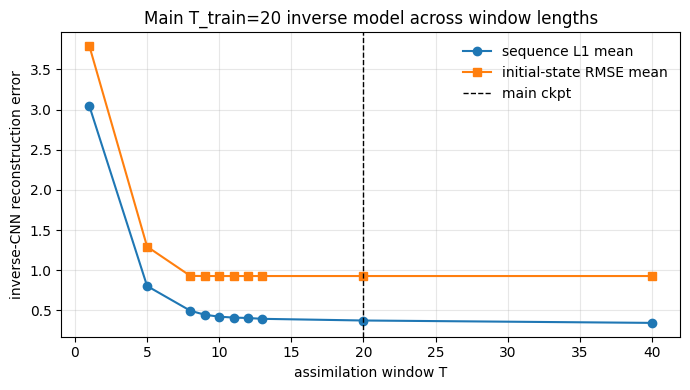

In [14]:
invobs_diag = []
inverter.eval()
with torch.no_grad():
    for T_assim in ASSIM_WINDOWS:
        Y_T = Y_eval[:, :T_assim]
        X_T = X_eval[:, :T_assim]
        X_inv = inverter(Y_T)
        seq_l1 = (X_inv - X_T).abs().mean(dim=(1, 2)).detach().cpu().numpy()
        x0_rmse = ((X_inv[:, 0] - X0_eval) ** 2).mean(dim=-1).sqrt().detach().cpu().numpy()
        invobs_diag.append({
            'window': T_assim,
            'seq_l1_mean': float(seq_l1.mean()),
            'seq_l1_p90': float(np.percentile(seq_l1, 90)),
            'x0_rmse_mean': float(x0_rmse.mean()),
            'x0_rmse_p90': float(np.percentile(x0_rmse, 90)),
        })

try:
    import pandas as pd
    df_invobs = pd.DataFrame(invobs_diag)
    display(df_invobs)
except Exception:
    for row in invobs_diag:
        print(row)

fig, ax = plt.subplots(figsize=(7, 4))
xs = [r['window'] for r in invobs_diag]
ax.plot(xs, [r['seq_l1_mean'] for r in invobs_diag], marker='o', label='sequence L1 mean')
ax.plot(xs, [r['x0_rmse_mean'] for r in invobs_diag], marker='s', label='initial-state RMSE mean')
ax.axvline(20, color='k', ls='--', lw=1.0, label='main ckpt')
ax.set_xlabel('assimilation window T')
ax.set_ylabel('inverse-CNN reconstruction error')
ax.set_title('Main T_train=20 inverse model across window lengths')
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

---
## Run Corrected Window Sweep

Each `(window, method)` pair is cached independently. Rerunning the notebook will load completed results and skip the expensive DA solve.

In [15]:
sweep_results = []
truth_by_window = {}

for T_assim in ASSIM_WINDOWS:
    Y_T = Y_eval[:, :T_assim]
    X_truth_total = X_eval[:, :T_assim + T_FORECAST]
    truth_by_window[T_assim] = {
        'X0': X0_eval.detach().cpu(),
        'X': X_truth_total.detach().cpu(),
        'Y': Y_T.detach().cpu(),
    }

    inits = {
        'baseline': baseline_init_l96(L96, Y_T),
        'invobs': invobs_init_l96(inverter, Y_T),
    }

    for method, cfg in METHODS.items():
        key = da_cache_key(T_assim, method)
        cached = None if FORCE_RECOMPUTE_DA else (load_cache(key) if USE_DA_CACHE else None)
        if cached is not None:
            row = cached['row']
            sweep_results.append(row)
            print(f'Loaded cache: T={T_assim}, {method}')
            print_result(row)
            continue

        print(f'\n=== T={T_assim} | {method} ===')
        t0 = time.time()
        X0_init = inits[cfg['init']]

        if OPTIMIZE_PER_SAMPLE:
            x0_opts = []
            sample_stage_diags = []
            for i in range(N_EVAL):
                X0_opt_i, diags_i = run_da_single(
                    L96, inverter, corr, X0_init[i], Y_T[i], T_assim,
                    physics_steps=cfg['p_steps'], obs_steps=cfg['o_steps'],
                )
                x0_opts.append(X0_opt_i.detach().cpu())
                sample_stage_diags.append(diags_i)
                if (i + 1) % max(1, N_EVAL // 4) == 0 or i == N_EVAL - 1:
                    print(f'  sample {i + 1}/{N_EVAL}')
            X0_opt = torch.stack(x0_opts, dim=0)
        else:
            X0_opt, sample_stage_diags = run_da_batched(
                L96, inverter, corr, X0_init, Y_T, T_assim,
                physics_steps=cfg['p_steps'], obs_steps=cfg['o_steps'],
            )
            X0_opt = X0_opt.detach().cpu()

        elapsed = time.time() - t0
        row = summarize_result(method, T_assim, X0_opt, X0_eval.cpu(), X_truth_total.cpu(), sample_stage_diags, elapsed)
        sweep_results.append(row)
        print_result(row)

        if SAVE_DA_CACHE:
            save_cache({'row': row, 'metadata': {'T_assim': T_assim, 'method': method}}, key)

print(f'\nLoaded/computed {len(sweep_results)} method-window results.')

  [cache] loaded l96_corrected_da_v2_batched_ckptl96_inverter_sigma0.0_n32000_ep500_T1_methodbaseline_init___observation_opt_N16_forecast40_sigma0.0_seed1706_p0_o200.pt
Loaded cache: T=1, baseline init + observation opt
T=  1 | baseline init + observation opt  | ok       forecast=3.9777 end_assim=3.2607 max_grad=3.018e-05 closures_mean=4.0 failures=0 time=5.2s
  [cache] loaded l96_corrected_da_v2_batched_ckptl96_inverter_sigma0.0_n32000_ep500_T1_methodinverse_init___observation_opt_N16_forecast40_sigma0.0_seed1706_p0_o200.pt
Loaded cache: T=1, inverse init + observation opt
T=  1 | inverse init + observation opt   | ok       forecast=3.5873 end_assim=2.3639 max_grad=1.819e+00 closures_mean=12.0 failures=0 time=0.0s
  [cache] loaded l96_corrected_da_v2_batched_ckptl96_inverter_sigma0.0_n32000_ep500_T1_methodbaseline_init___hybrid_opt_N16_forecast40_sigma0.0_seed1706_p50_o150.pt
Loaded cache: T=1, baseline init + hybrid opt
T=  1 | baseline init + hybrid opt       | ok       forecast=3.5

---
## Summary Table

In [16]:
summary_cols = [
    'window', 'method', 'status', 'exploded', 'failed_count',
    'x0_rmse_mean', 'x0_rmse_median', 'assim_l1_mean', 'end_assim_l1_mean',
    'forecast_l1_mean', 'forecast_l1_median', 'forecast_l1_p90', 'final_l1_mean',
    'max_grad_norm', 'grad_norm_p90_sample', 'closures_mean', 'closures_max', 'elapsed_s',
]
summary_rows = [{k: row[k] for k in summary_cols} for row in sweep_results]

try:
    import pandas as pd
    df_summary = pd.DataFrame(summary_rows).sort_values(['window', 'method'])
    display(df_summary)
except Exception:
    df_summary = None
    for row in summary_rows:
        print(row)

,window,method,status,exploded,failed_count,x0_rmse_mean,x0_rmse_median,assim_l1_mean,end_assim_l1_mean,forecast_l1_mean,forecast_l1_median,forecast_l1_p90,final_l1_mean,max_grad_norm,grad_norm_p90_sample,closures_mean,closures_max,elapsed_s
2,1,baseline init + hybrid opt,ok,False,0,3.369050,3.311535,2.363858,2.363858,3.587286,3.655214,3.961903,4.241974,1.818723,1.818723,37.0,37,0.090177
0,1,baseline init + observation opt,ok,False,0,4.568730,4.524374,3.260749,3.260749,3.977732,3.995214,4.194993,3.873658,0.000030,0.000030,4.0,4,5.182652
3,1,inverse init + hybrid opt,ok,False,0,3.369048,3.311532,2.363856,2.363856,3.587293,3.655212,3.961909,4.241971,1.818721,1.818721,25.0,25,0.053480
1,1,inverse init + observation opt,ok,False,0,3.369046,3.311530,2.363854,2.363854,3.587305,3.655208,3.961923,4.241993,1.818716,1.818716,12.0,12,0.025439
6,5,baseline init + hybrid opt,ok,False,0,0.803600,0.469317,0.409988,0.436885,2.592463,2.517350,3.421370,3.896678,1.809159,1.809159,207.0,207,10.992358
4,5,baseline init + observation opt,ok,False,0,4.781293,4.931529,2.998653,2.823230,3.857591,3.878191,4.255833,4.029591,2.692294,2.692294,209.0,209,11.168513
7,5,inverse init + hybrid opt,ok,False,0,0.804766,0.468090,0.411237,0.439315,2.568380,2.605213,3.387083,3.956036,0.559229,0.559229,210.0,210,11.119842
5,5,inverse init + observation opt,ok,False,0,0.822756,0.501582,0.418720,0.443993,2.377544,2.288757,3.311459,3.585793,0.809050,0.809050,211.0,211,11.214400
10,8,baseline init + hybrid opt,ok,False,0,1.027902,0.623699,0.350442,0.280896,2.220997,2.212571,2.933513,3.636505,2.427626,2.427626,212.0,212,19.074929
8,8,baseline init + observation opt,ok,False,0,4.548435,4.614027,2.894246,2.651739,3.881192,3.865399,4.322891,4.140904,9.065687,9.065687,216.0,216,19.630897


## Heatmaps

Heatmaps are the fastest way to see method/window patterns: forecast skill, analysis error at the end of the assimilation window, gradient size, and optimizer work.

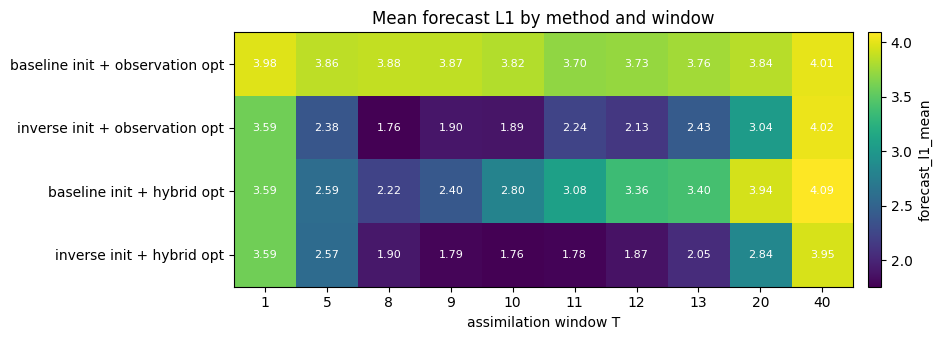

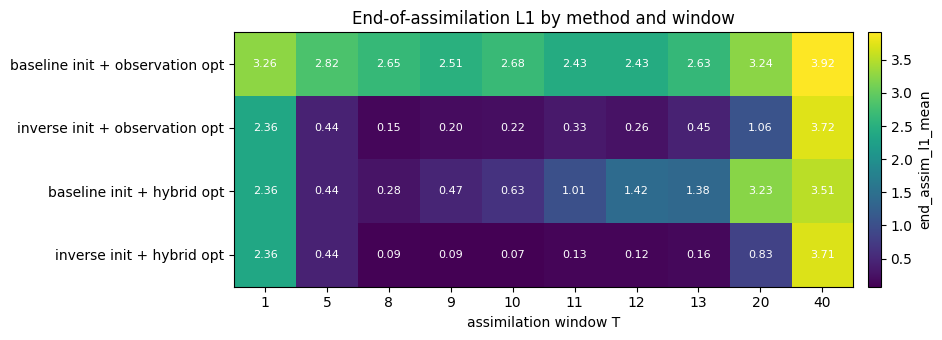

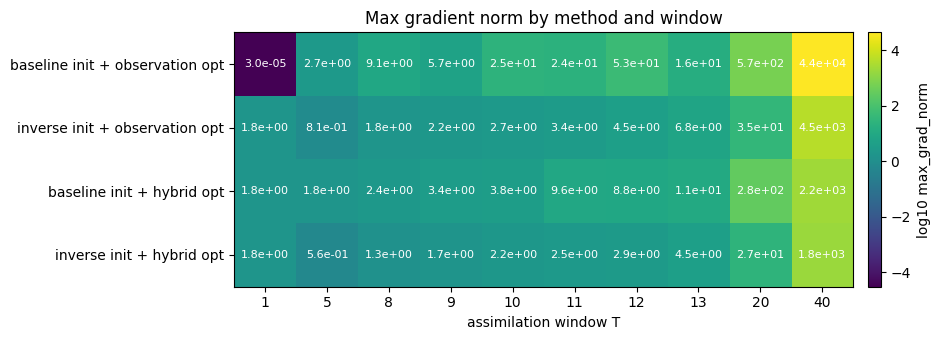

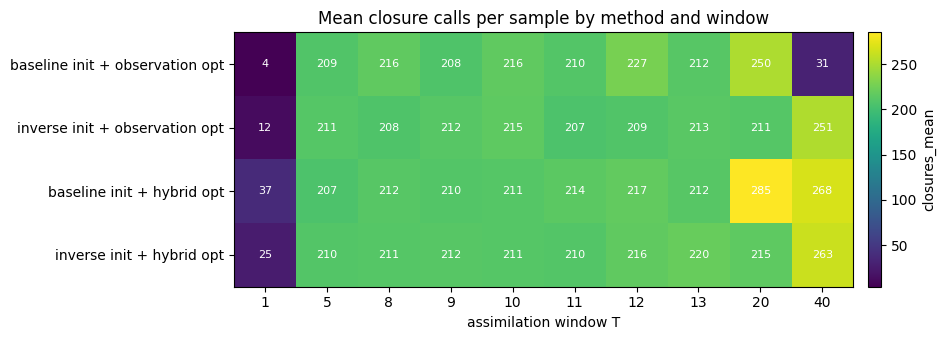

In [17]:
def plot_metric_heatmap(metric, title, log=False, fmt='.2f'):
    if df_summary is None:
        print('pandas is needed for this heatmap helper')
        return
    pivot = df_summary.pivot(index='method', columns='window', values=metric).loc[list(METHODS.keys())]
    values = pivot.values.astype(float)
    plot_values = np.log10(values) if log else values
    fig, ax = plt.subplots(figsize=(10, 3.5))
    im = ax.imshow(plot_values, aspect='auto', cmap='viridis')
    ax.set_xticks(np.arange(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(np.arange(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel('assimilation window T')
    ax.set_title(title)
    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.set_label(('log10 ' if log else '') + metric)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            label_value = values[i, j]
            txt = f'{label_value:.1e}' if log else format(label_value, fmt)
            ax.text(j, i, txt, ha='center', va='center', color='white', fontsize=8)
    plt.tight_layout()
    plt.show()

plot_metric_heatmap('forecast_l1_mean', 'Mean forecast L1 by method and window')
plot_metric_heatmap('end_assim_l1_mean', 'End-of-assimilation L1 by method and window')
plot_metric_heatmap('max_grad_norm', 'Max gradient norm by method and window', log=True)
plot_metric_heatmap('closures_mean', 'Mean closure calls per sample by method and window', fmt='.0f')

## Per-Sample Forecast Error Distributions

Means can hide outlier trajectories. These boxplots show the distribution of forecast error across shared samples.

/tmp/ipykernel_3323/3816004368.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels, showfliers=True, whis=(5, 95))
/tmp/ipykernel_3323/3816004368.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels, showfliers=True, whis=(5, 95))
/tmp/ipykernel_3323/3816004368.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=labels, showfliers=True, whis=(5, 95))
/tmp/ipykernel_3323/3816004368.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will b

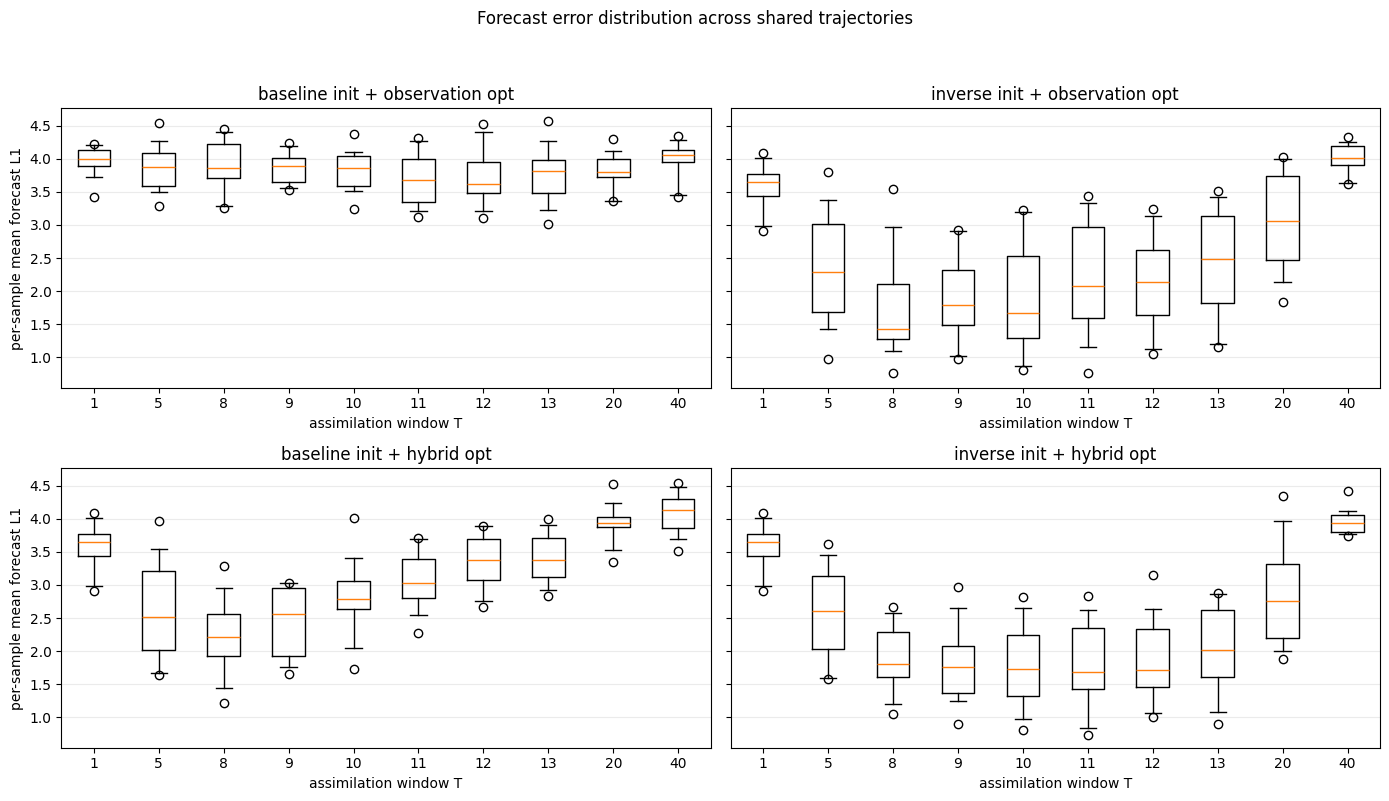

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
axes = axes.ravel()

for ax, method in zip(axes, METHODS):
    rows = [r for r in sweep_results if r['method'] == method]
    rows = sorted(rows, key=lambda r: r['window'])
    data = [r['forecast_l1_samples'] for r in rows]
    labels = [str(r['window']) for r in rows]
    ax.boxplot(data, labels=labels, showfliers=True, whis=(5, 95))
    ax.set_title(method)
    ax.set_xlabel('assimilation window T')
    ax.grid(alpha=0.25, axis='y')

axes[0].set_ylabel('per-sample mean forecast L1')
axes[2].set_ylabel('per-sample mean forecast L1')
fig.suptitle('Forecast error distribution across shared trajectories', y=0.995)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## Forecast-Start-Aligned Curves

Each curve starts at lead `0` after the assimilation window ends. This separates forecast quality from the length of the assimilation period.

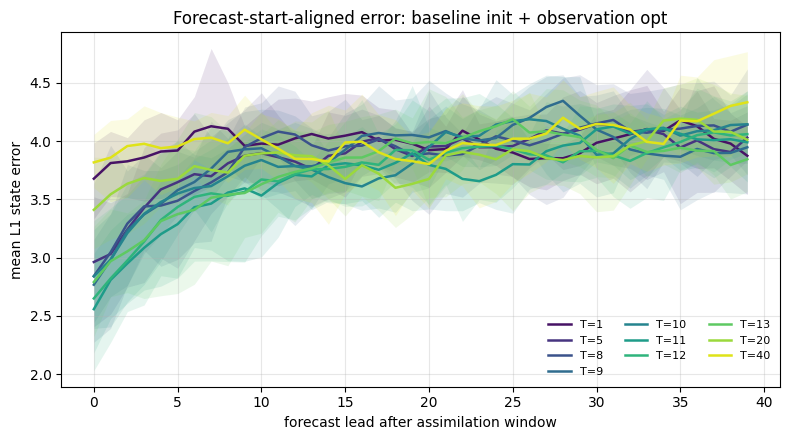

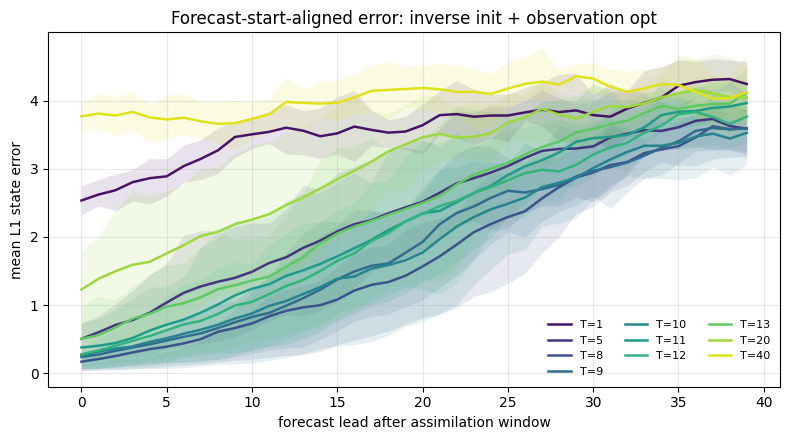

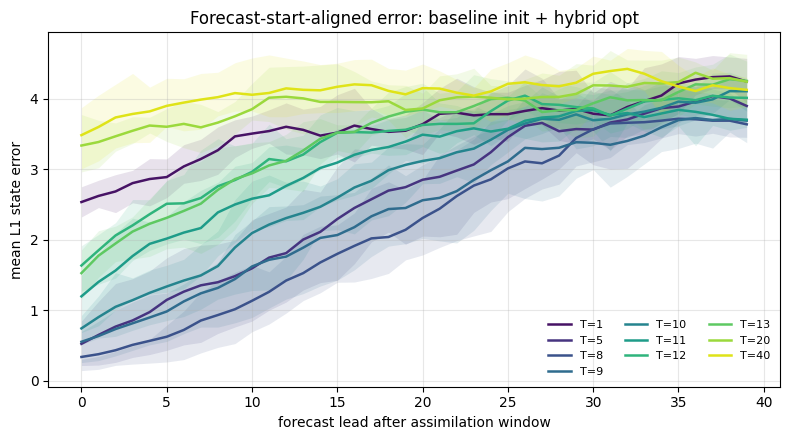

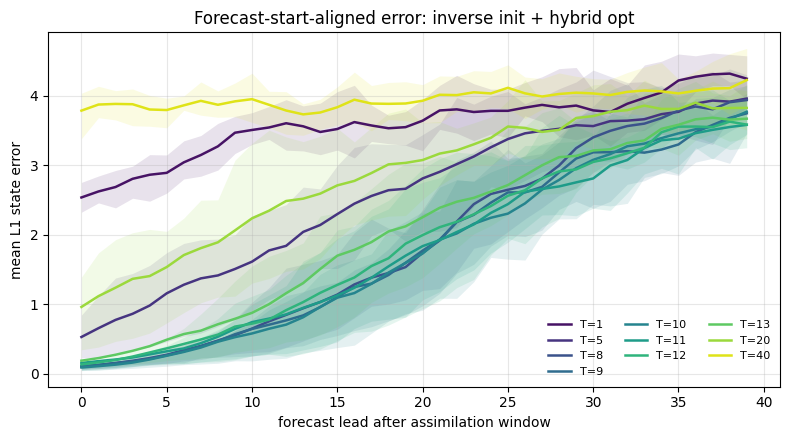

In [19]:
FORECAST_CURVE_WINDOWS = ASSIM_WINDOWS
window_colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(FORECAST_CURVE_WINDOWS)))

for method in METHODS:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for color, T_assim in zip(window_colors, FORECAST_CURVE_WINDOWS):
        row = next((r for r in sweep_results if r['method'] == method and r['window'] == T_assim), None)
        if row is None:
            continue
        forecast_err = row['l1_t_samples'][:, T_assim:]
        mean = forecast_err.mean(axis=0)
        q25 = np.percentile(forecast_err, 25, axis=0)
        q75 = np.percentile(forecast_err, 75, axis=0)
        lead = np.arange(len(mean))
        ax.plot(lead, mean, color=color, lw=1.8, label=f'T={T_assim}')
        ax.fill_between(lead, q25, q75, color=color, alpha=0.12, linewidth=0)
    ax.set_title(f'Forecast-start-aligned error: {method}')
    ax.set_xlabel('forecast lead after assimilation window')
    ax.set_ylabel('mean L1 state error')
    ax.grid(alpha=0.3)
    ax.legend(ncol=3, frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()

## Assimilation-Plus-Forecast Rollout Error

These curves keep the original absolute time axis and mark the assimilation/forecast split.

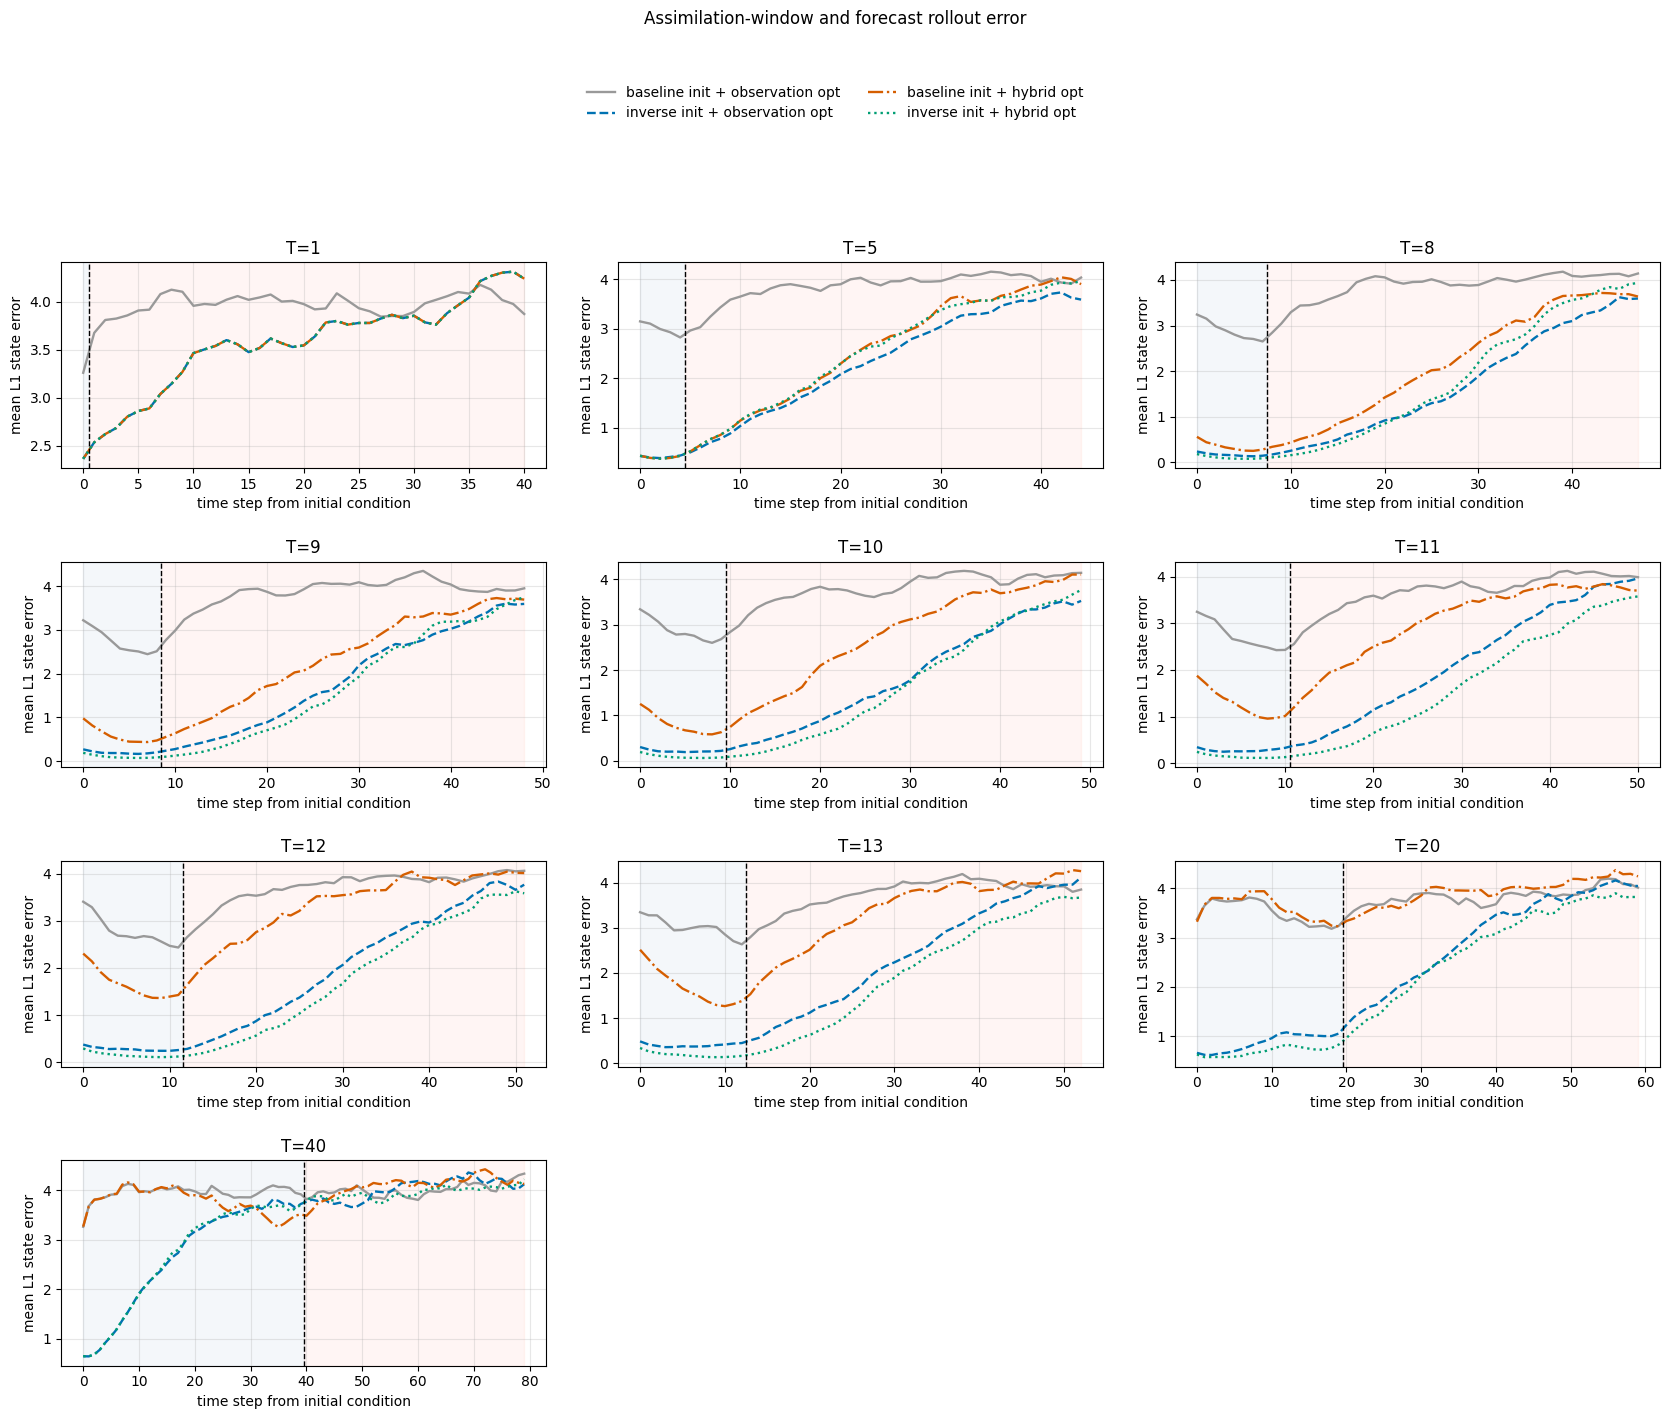

In [20]:
ROLLOUT_ERROR_WINDOWS = ASSIM_WINDOWS
ncols = 3
nrows = math.ceil(len(ROLLOUT_ERROR_WINDOWS) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5.6 * ncols, 3.5 * nrows), sharey=False)
axes = np.atleast_1d(axes).ravel()

for ax, T_show in zip(axes, ROLLOUT_ERROR_WINDOWS):
    rows = [r for r in sweep_results if r['window'] == T_show]
    for row in rows:
        l1_t = np.asarray(row['l1_t'])
        lead = np.arange(len(l1_t))
        ax.plot(lead, l1_t, color=colors[row['method']], linestyle=linestyles[row['method']], lw=1.7, label=row['method'])
    sep = T_show - 0.5
    ax.axvline(sep, color='k', lw=1.0, ls='--')
    ax.axvspan(0, sep, alpha=0.06, color='steelblue')
    ax.axvspan(sep, T_show + T_FORECAST - 1, alpha=0.06, color='tomato')
    ax.set_title(f'T={T_show}')
    ax.set_xlabel('time step from initial condition')
    ax.set_ylabel('mean L1 state error')
    ax.grid(alpha=0.3)

for ax in axes[len(ROLLOUT_ERROR_WINDOWS):]:
    ax.axis('off')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.965), ncol=2, frameon=False)
fig.suptitle('Assimilation-window and forecast rollout error', y=1.01)
plt.tight_layout(rect=(0, 0, 1, 0.88), w_pad=2.0, h_pad=2.0)
plt.show()

## Stage-Separated Loss and Gradient Diagnostics

Hybrid optimization has a physics stage and an observation stage. Keeping them separate helps identify which stage is causing large gradients or early stopping.

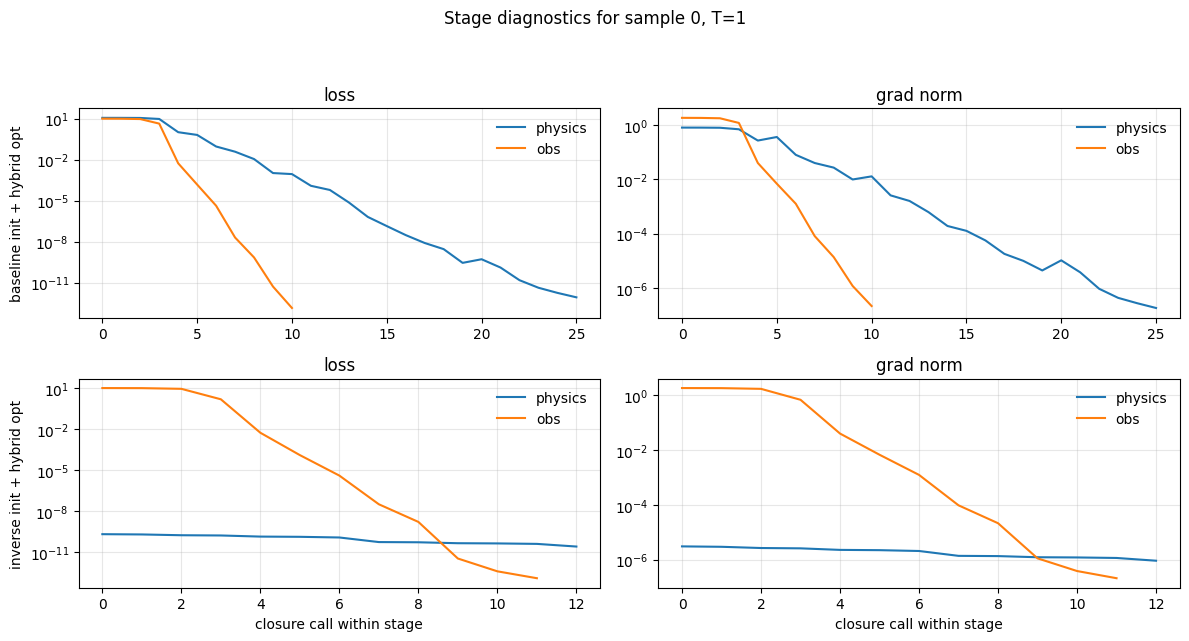

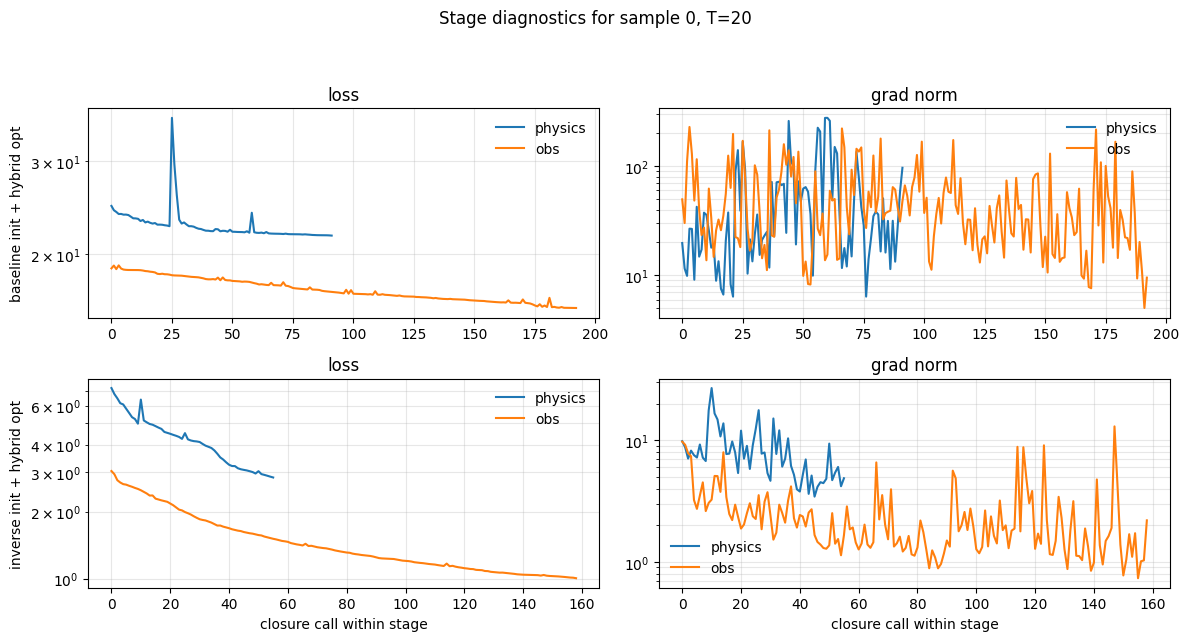

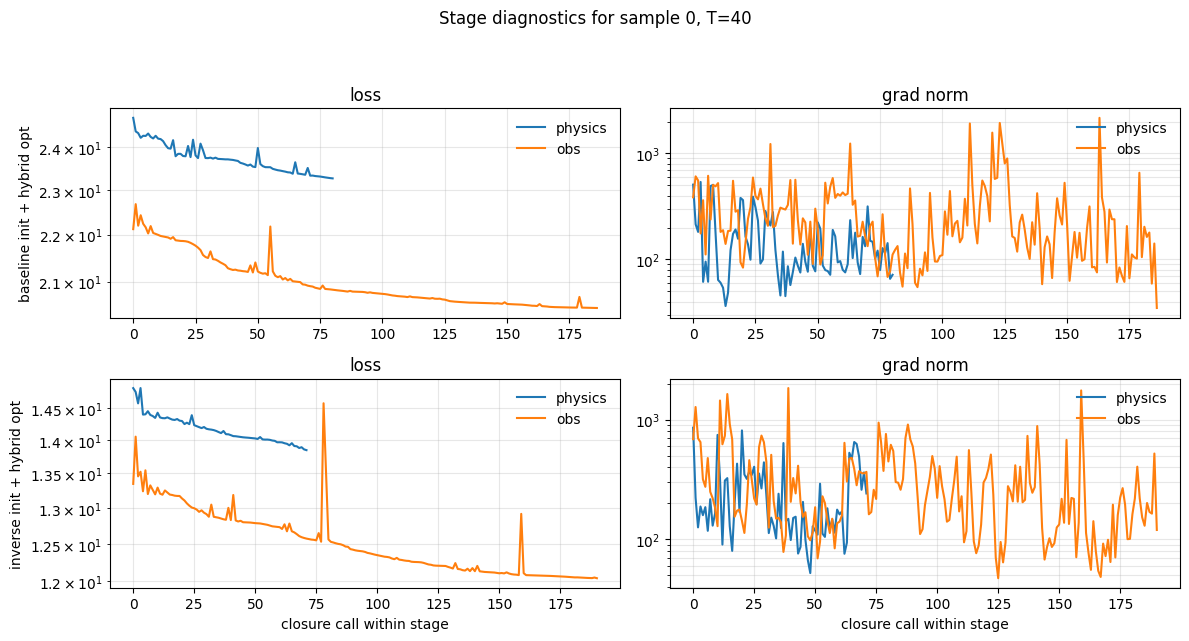

In [21]:
DIAG_WINDOWS = [ASSIM_WINDOWS[0], 20 if 20 in ASSIM_WINDOWS else ASSIM_WINDOWS[len(ASSIM_WINDOWS)//2], ASSIM_WINDOWS[-1]]
DIAG_METHODS = ['baseline init + hybrid opt', 'inverse init + hybrid opt']
DIAG_SAMPLE_IDX = 0

for T_show in DIAG_WINDOWS:
    fig, axes = plt.subplots(len(DIAG_METHODS), 2, figsize=(12, 3.2 * len(DIAG_METHODS)), squeeze=False)
    for row_i, method in enumerate(DIAG_METHODS):
        row = next((r for r in sweep_results if r['window'] == T_show and r['method'] == method), None)
        if row is None:
            continue
        sample_diags = row['sample_stage_diags'][DIAG_SAMPLE_IDX]
        for diag in sample_diags:
            stage = diag.get('stage', 'stage')
            losses = diag.get('loss', [])
            grads = diag.get('grad_norm', [])
            if losses:
                axes[row_i, 0].plot(losses, label=stage)
            if grads:
                axes[row_i, 1].plot(grads, label=stage)
        axes[row_i, 0].set_yscale('log')
        axes[row_i, 1].set_yscale('log')
        axes[row_i, 0].set_ylabel(method)
        axes[row_i, 0].set_title('loss')
        axes[row_i, 1].set_title('grad norm')
        axes[row_i, 0].grid(alpha=0.3, which='both')
        axes[row_i, 1].grid(alpha=0.3, which='both')
        axes[row_i, 0].legend(frameon=False)
        axes[row_i, 1].legend(frameon=False)
    axes[-1, 0].set_xlabel('closure call within stage')
    axes[-1, 1].set_xlabel('closure call within stage')
    fig.suptitle(f'Stage diagnostics for sample {DIAG_SAMPLE_IDX}, T={T_show}', y=0.995)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

## Rollout and Residual Hovmoller Views

These show one trajectory at a time. The residual image (`prediction - truth`) is often easier to read than the raw state plot.

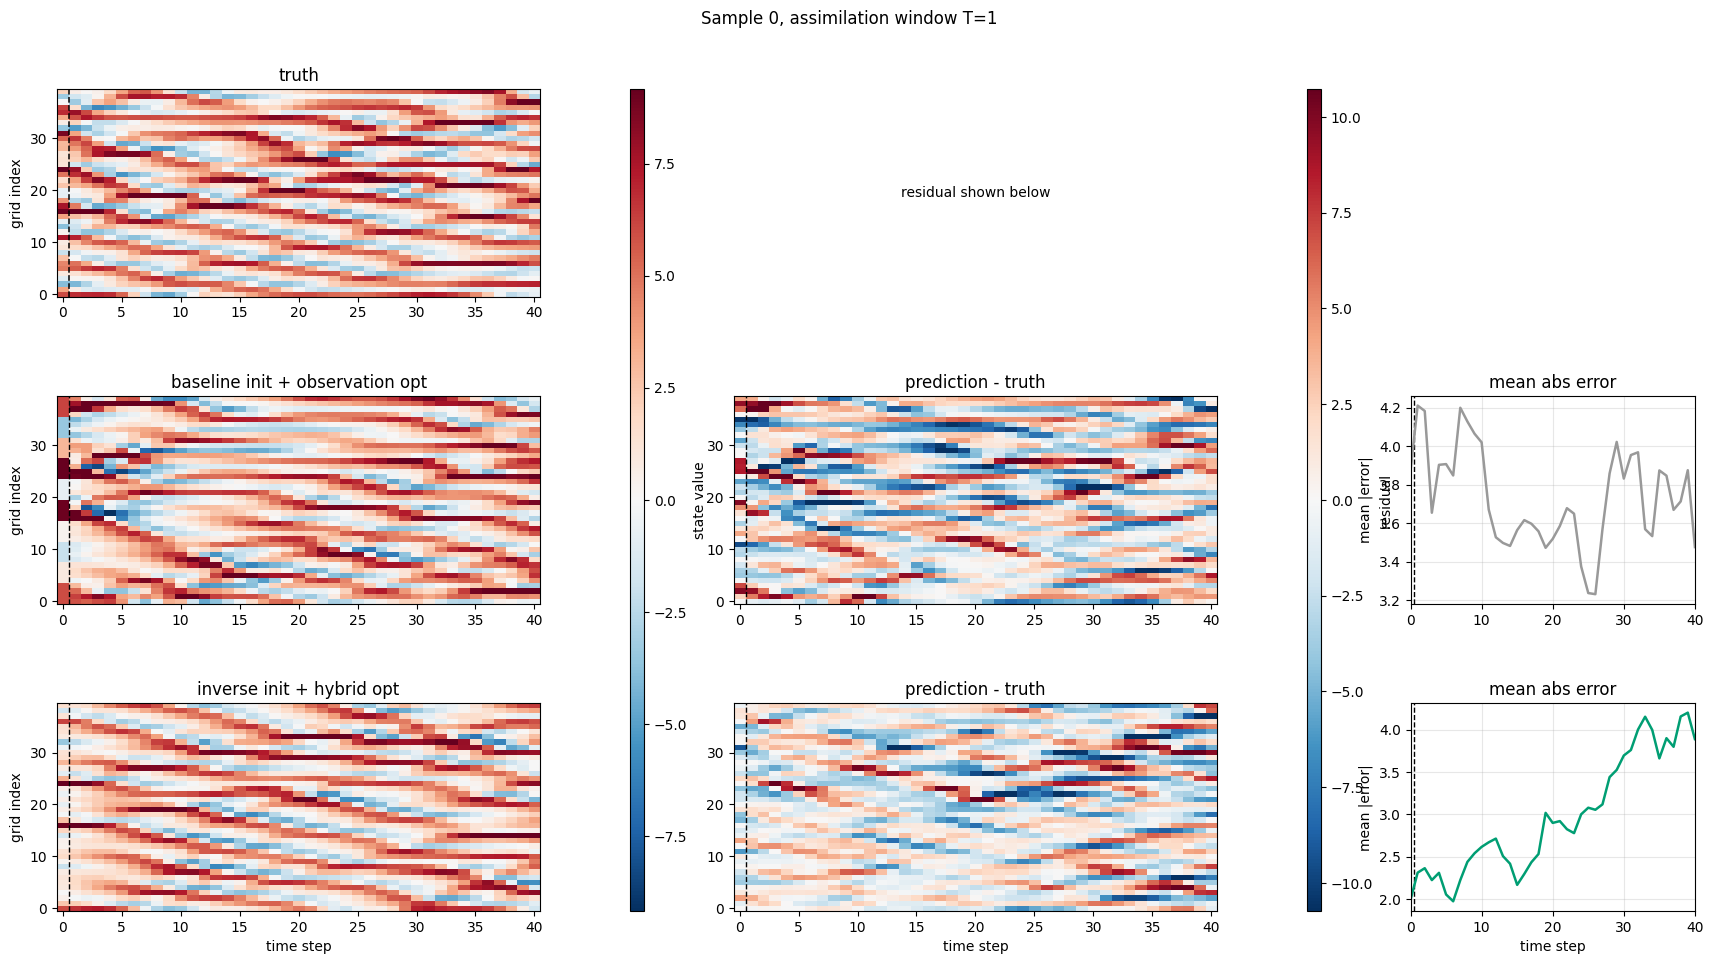

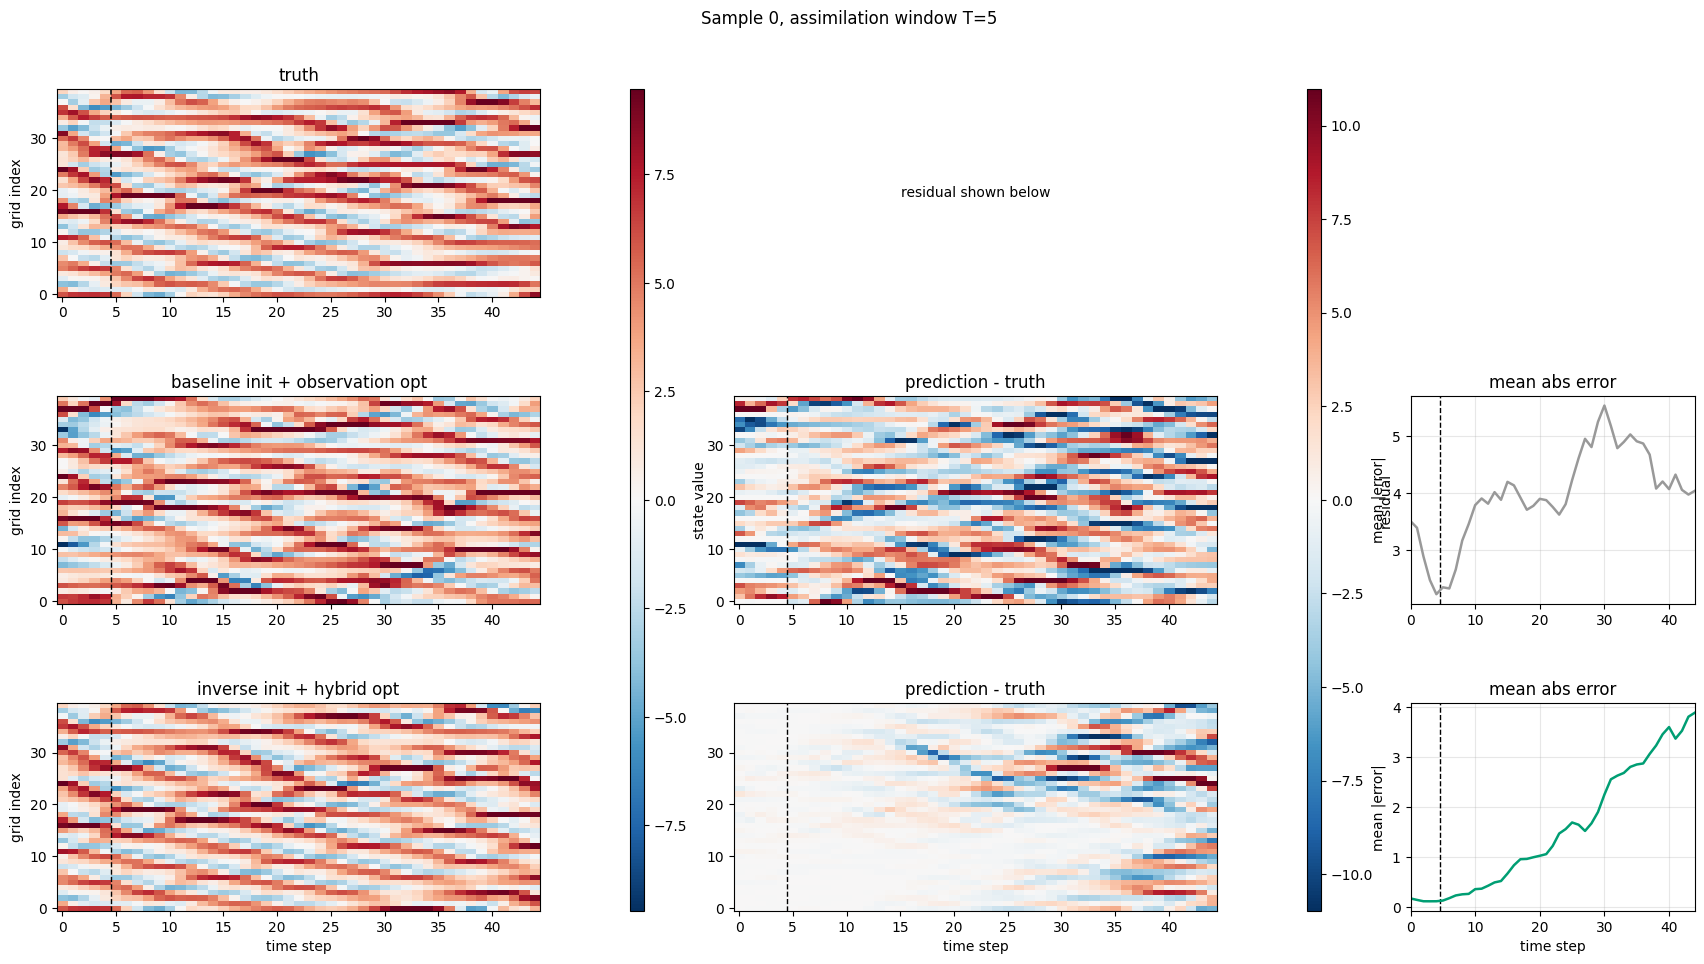

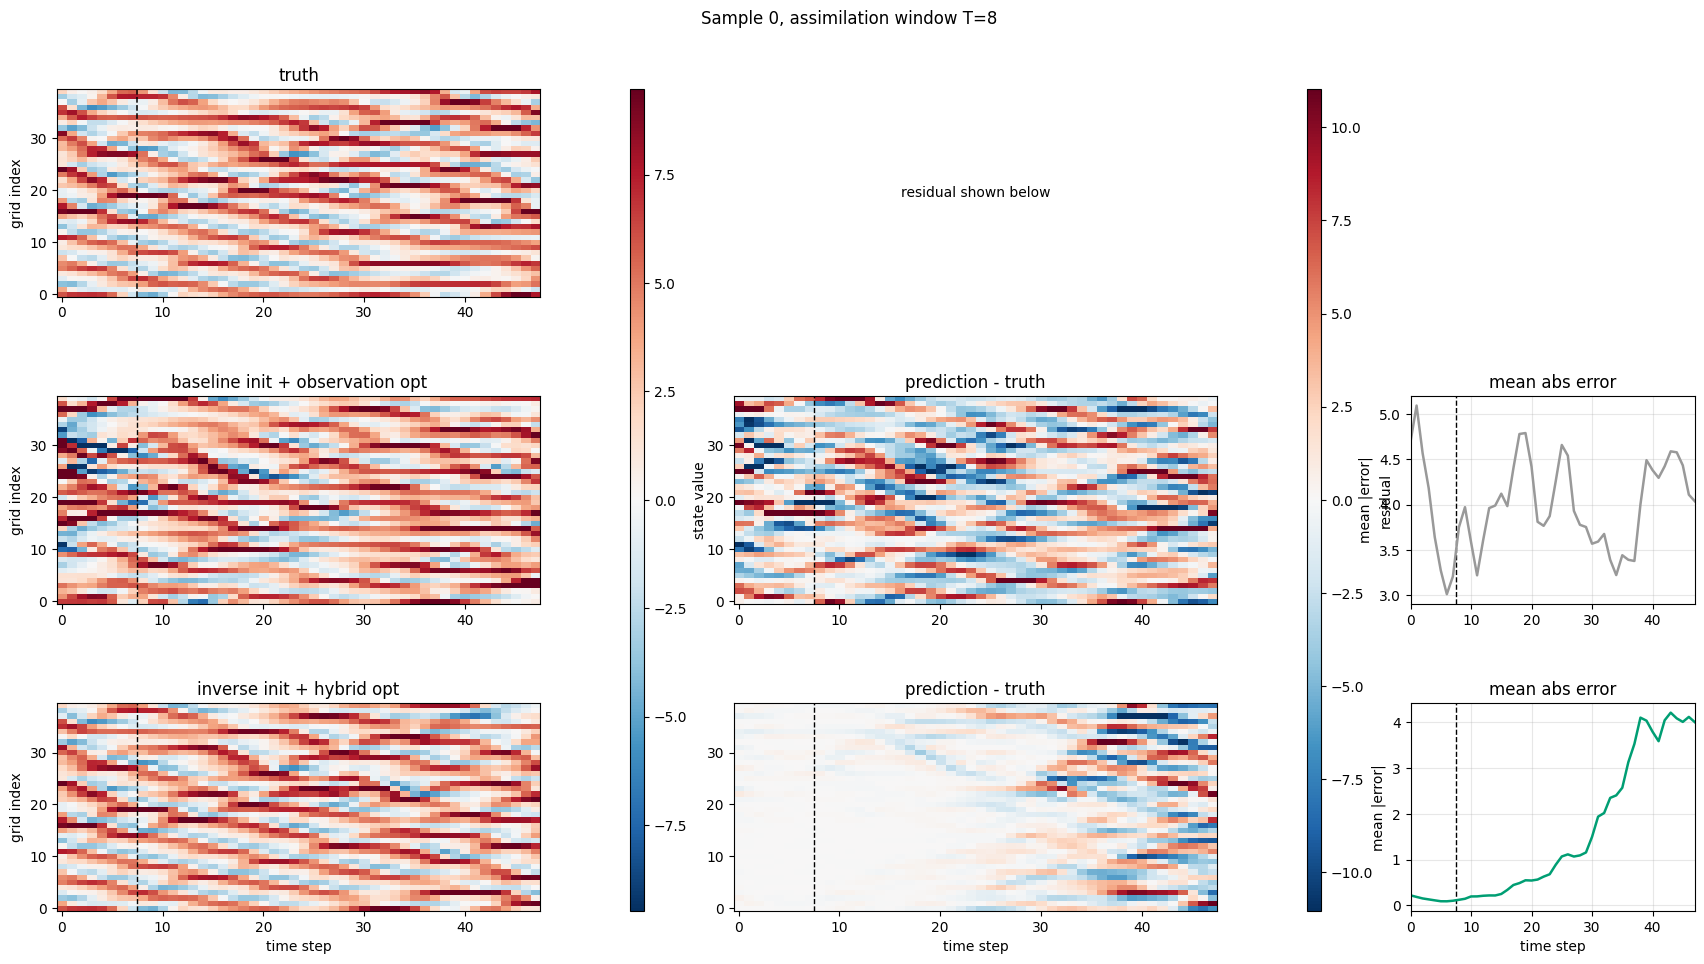

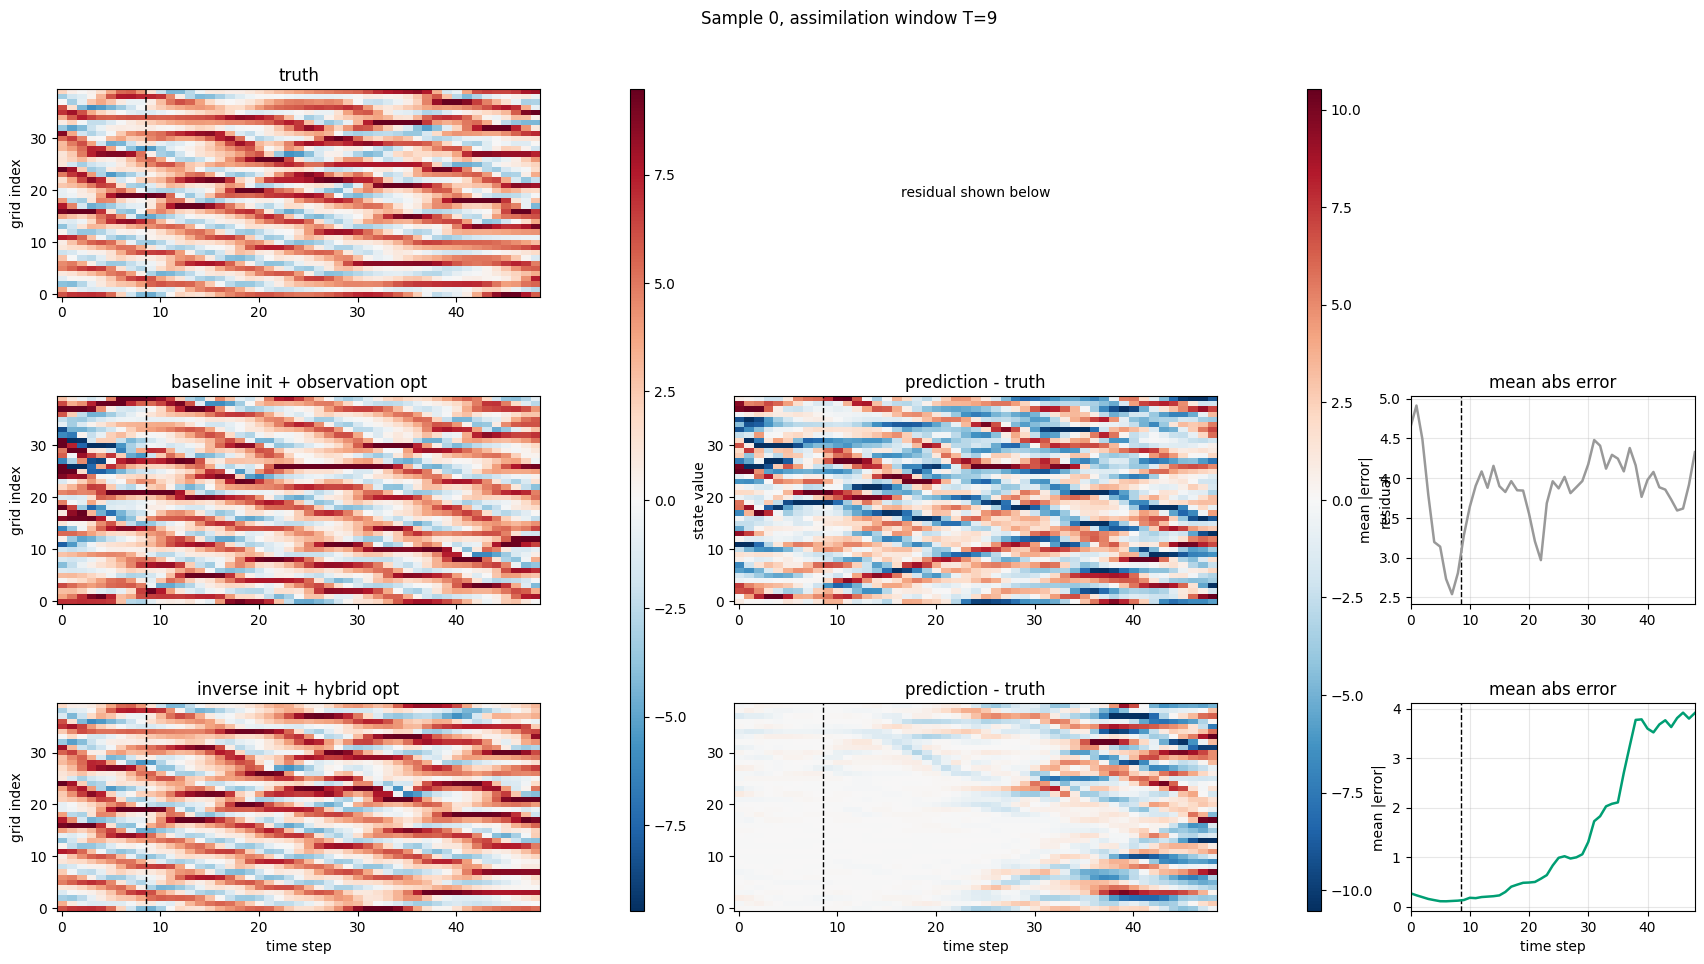

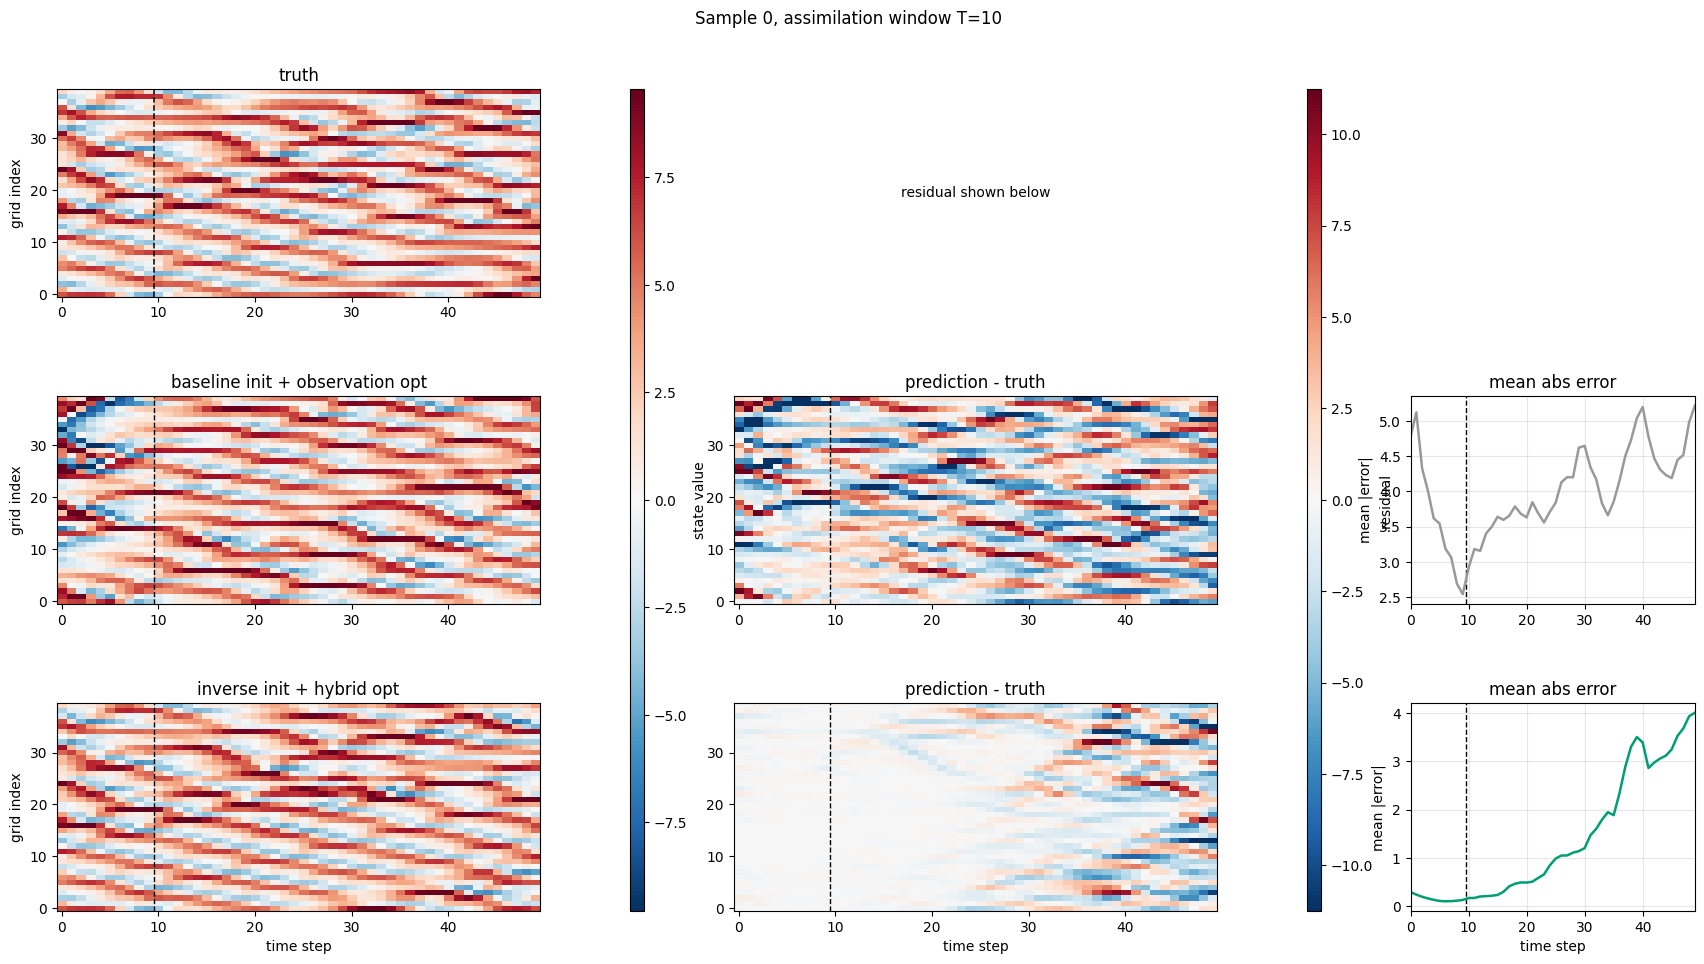

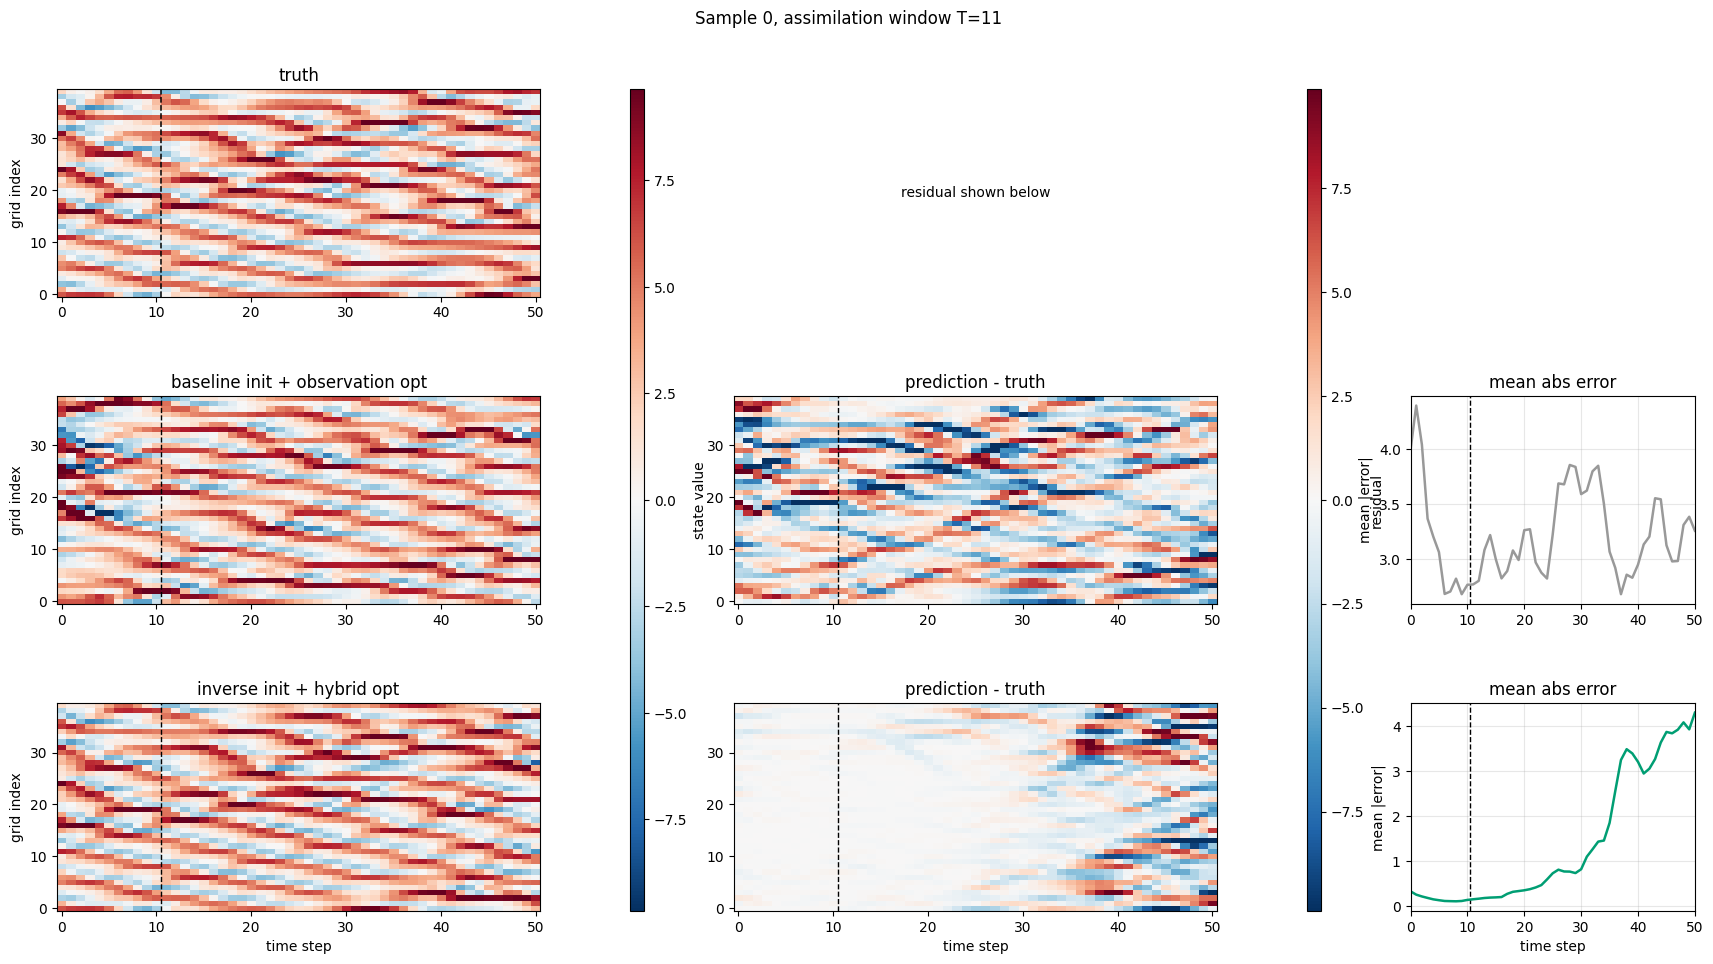

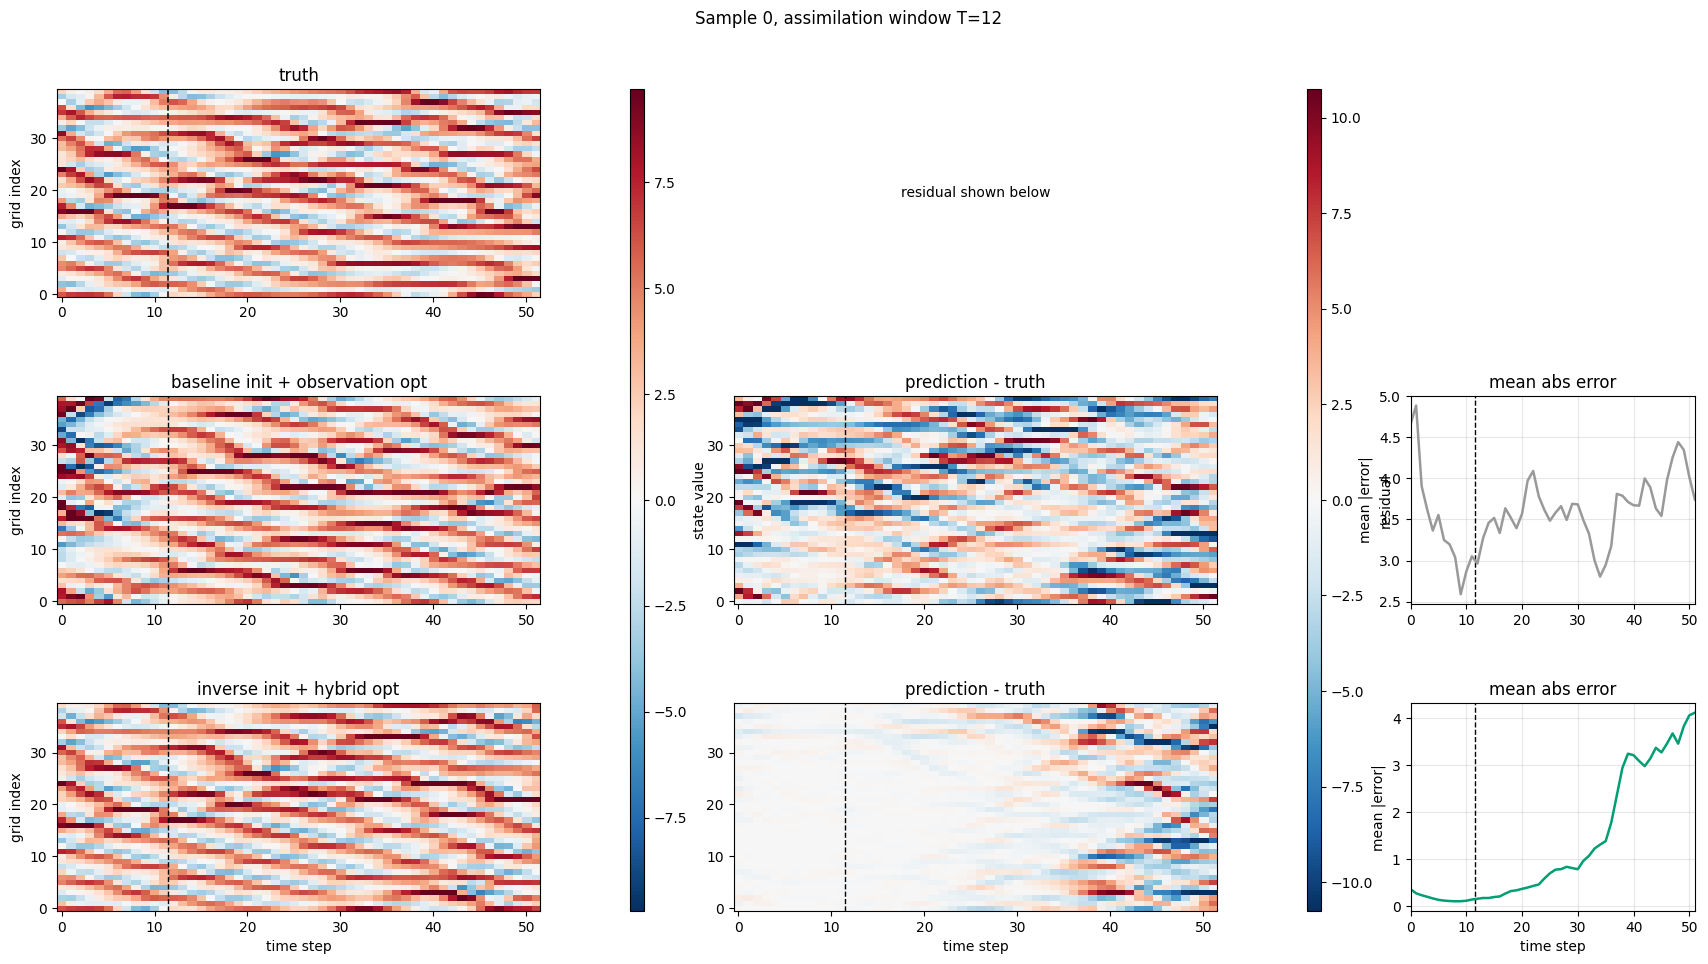

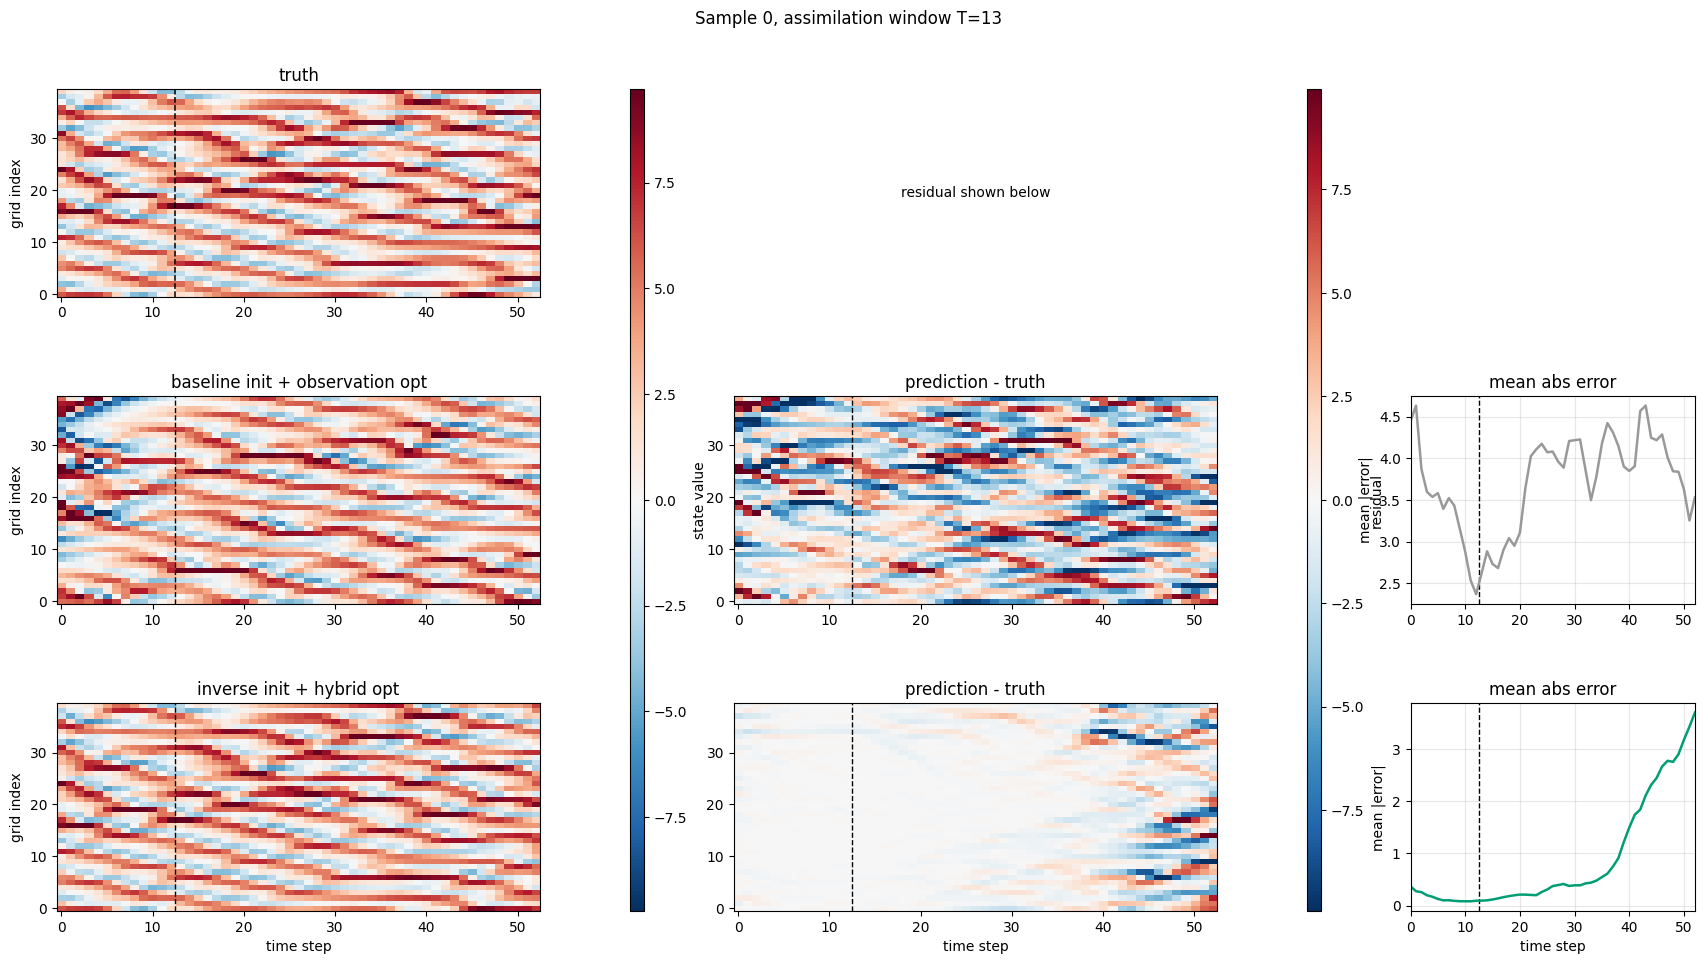

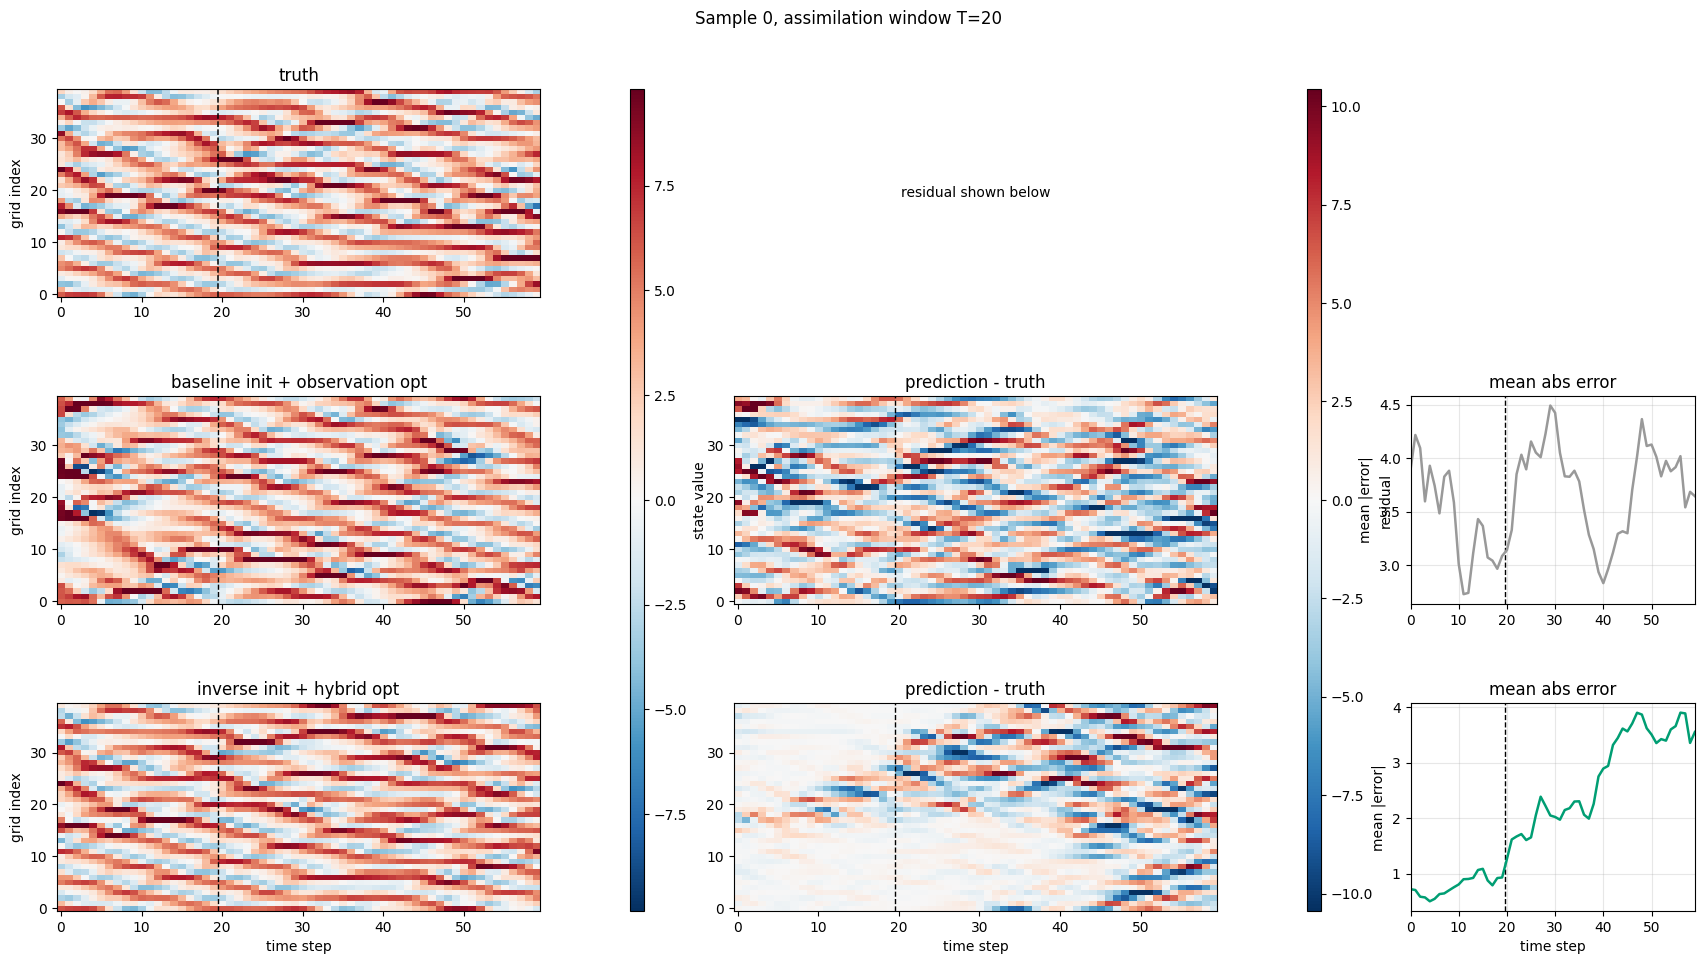

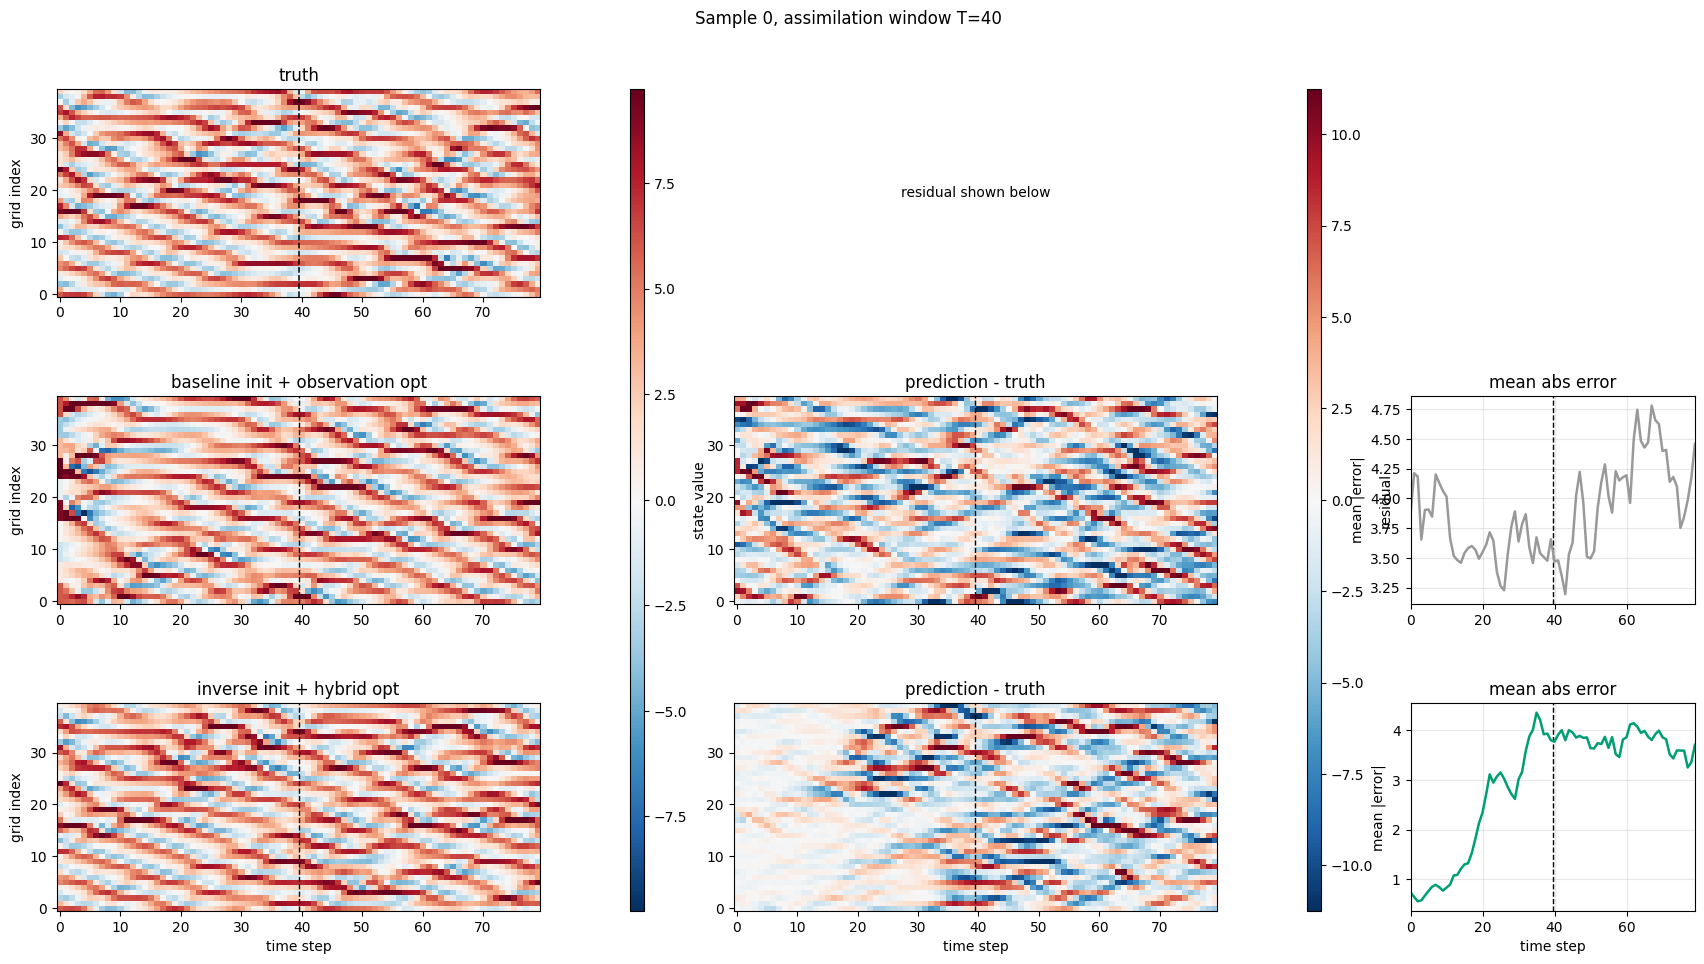

In [22]:
ROLLOUT_STATE_WINDOWS = [t for t in [1, 5, 8, 9, 10, 11, 12, 13, 20, 40] if t in ASSIM_WINDOWS]
ROLLOUT_STATE_METHODS = ['baseline init + observation opt', 'inverse init + hybrid opt']
ROLLOUT_SAMPLE_IDX = 0

for T_show in ROLLOUT_STATE_WINDOWS:
    truth = truth_by_window[T_show]
    X_truth_total = truth['X'].to(device)
    T_total = T_show + T_FORECAST
    truth_traj = X_truth_total[ROLLOUT_SAMPLE_IDX].detach().cpu().numpy()
    rows_by_method = {r['method']: r for r in sweep_results if r['window'] == T_show}

    panels = []
    for method in ROLLOUT_STATE_METHODS:
        row = rows_by_method.get(method)
        if row is None:
            continue
        x0_opt = row['x0_opt'][ROLLOUT_SAMPLE_IDX].to(device)
        pred_traj = L96.integrate(x0_opt, T_total).detach().cpu().numpy()
        residual = pred_traj - truth_traj
        err_t = np.abs(residual).mean(axis=1)
        panels.append((method, pred_traj, residual, err_t))

    state_vlim = np.nanpercentile(np.abs(truth_traj), 98)
    resid_vlim = max(1e-6, np.nanpercentile(np.abs([p[2] for p in panels]), 98)) if panels else 1.0
    fig = plt.figure(figsize=(18, 3.3 * (len(panels) + 1)), constrained_layout=False)
    gs = fig.add_gridspec(len(panels) + 1, 5, width_ratios=[3.4, 0.10, 3.4, 0.10, 2.0], wspace=0.35, hspace=0.48)
    cax_state = fig.add_subplot(gs[:, 1])
    cax_resid = fig.add_subplot(gs[:, 3])

    ax_truth = fig.add_subplot(gs[0, 0])
    im_state = ax_truth.imshow(truth_traj.T, aspect='auto', cmap='RdBu_r', vmin=-state_vlim, vmax=state_vlim, origin='lower', interpolation='nearest')
    ax_truth.axvline(T_show - 0.5, color='k', lw=1.1, ls='--')
    ax_truth.set_title('truth')
    ax_truth.set_ylabel('grid index')
    ax_blank = fig.add_subplot(gs[0, 2])
    ax_blank.axis('off')
    ax_blank.text(0.5, 0.5, 'residual shown below', ha='center', va='center')
    ax_err_blank = fig.add_subplot(gs[0, 4])
    ax_err_blank.axis('off')

    im_resid = None
    for i, (method, pred_traj, residual, err_t) in enumerate(panels, start=1):
        ax_pred = fig.add_subplot(gs[i, 0])
        ax_resid = fig.add_subplot(gs[i, 2])
        ax_err = fig.add_subplot(gs[i, 4])
        ax_pred.imshow(pred_traj.T, aspect='auto', cmap='RdBu_r', vmin=-state_vlim, vmax=state_vlim, origin='lower', interpolation='nearest')
        im_resid = ax_resid.imshow(residual.T, aspect='auto', cmap='RdBu_r', vmin=-resid_vlim, vmax=resid_vlim, origin='lower', interpolation='nearest')
        for ax in [ax_pred, ax_resid, ax_err]:
            ax.axvline(T_show - 0.5, color='k', lw=1.0, ls='--')
        ax_pred.set_title(method)
        ax_resid.set_title('prediction - truth')
        ax_err.plot(err_t, color=colors.get(method, '#333333'), lw=1.8)
        ax_err.set_title('mean abs error')
        ax_err.set_ylabel('mean |error|')
        ax_err.set_xlim(0, T_total - 1)
        ax_err.grid(alpha=0.3)
        ax_pred.set_ylabel('grid index')
        if i == len(panels):
            ax_pred.set_xlabel('time step')
            ax_resid.set_xlabel('time step')
            ax_err.set_xlabel('time step')

    fig.colorbar(im_state, cax=cax_state).set_label('state value')
    if im_resid is not None:
        fig.colorbar(im_resid, cax=cax_resid).set_label('residual')
    fig.suptitle(f'Sample {ROLLOUT_SAMPLE_IDX}, assimilation window T={T_show}', y=0.98)
    fig.subplots_adjust(top=0.90, left=0.06, right=0.97, bottom=0.07)
    plt.show()

## Forecast Error vs. Gradient Diagnostics

This checks whether large forecast errors are associated with large gradients or many closure calls.

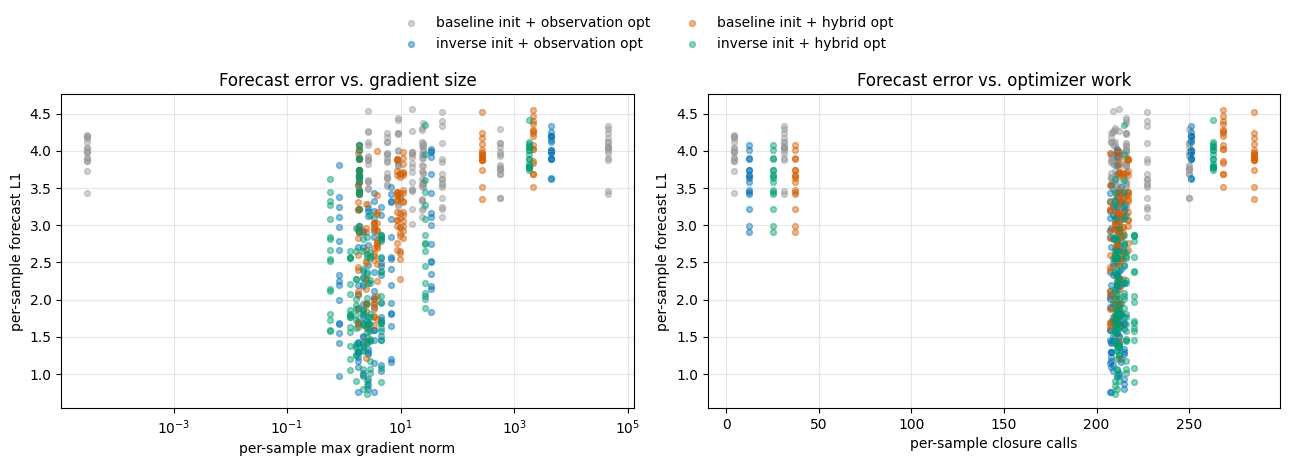

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for method in METHODS:
    rows = [r for r in sweep_results if r['method'] == method]
    x_grad = np.concatenate([r['max_grad_norm_samples'] for r in rows])
    x_close = np.concatenate([r['closure_counts'] for r in rows])
    y_err = np.concatenate([r['forecast_l1_samples'] for r in rows])
    axes[0].scatter(x_grad, y_err, s=18, alpha=0.45, color=colors[method], label=method)
    axes[1].scatter(x_close, y_err, s=18, alpha=0.45, color=colors[method], label=method)

axes[0].set_xscale('log')
axes[0].set_xlabel('per-sample max gradient norm')
axes[0].set_ylabel('per-sample forecast L1')
axes[0].set_title('Forecast error vs. gradient size')
axes[0].grid(alpha=0.3, which='both')
axes[1].set_xlabel('per-sample closure calls')
axes[1].set_ylabel('per-sample forecast L1')
axes[1].set_title('Forecast error vs. optimizer work')
axes[1].grid(alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.04), ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

---
## Notes For Interpretation

- If a longer window improves `end_assim_l1_mean` but not forecast-start-aligned curves, it is fitting the window without improving forecast stability.
- If `max_grad_norm` or `grad_norm_p90_sample` grows sharply with `T`, the algorithm is becoming harder to optimize even if the mean error still looks acceptable.
- If the boxplots show long upper tails, a mean-only plot is hiding failed or chaotic trajectories.
- If inverse-CNN reconstruction error grows far from `T_train=20`, hybrid behavior may reflect inverse-model distribution shift rather than only DA optimization difficulty.
- Full 4D-Var would add background and observation covariance terms; those would change the tradeoff between trusting the initial guess and trusting observations, especially with noisy data.